# Loan Repayment Analysis

## 1. Raw Data Audit

In [1]:
from pathlib import Path
import hashlib

import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.max_rows", 30)
pd.set_option("display.max_columns", 16)

SOURCE_PATH = Path("data/loan_data.csv")
TARGET = "not.fully.paid"
EXPECTED_FIELDS = [
    "credit.policy", "purpose", "int.rate", "installment",
    "log.annual.inc", "dti", "fico", "days.with.cr.line",
    "revol.bal", "revol.util", "inq.last.6mths",
    "delinq.2yrs", "pub.rec", TARGET,
]

source_sha256 = hashlib.sha256(SOURCE_PATH.read_bytes()).hexdigest()
raw_text = pd.read_csv(SOURCE_PATH, dtype="string", keep_default_na=False)
loans = pd.read_csv(SOURCE_PATH)

assert loans.columns.tolist() == EXPECTED_FIELDS
assert raw_text.columns.tolist() == EXPECTED_FIELDS

display(pd.DataFrame({
    "Records": [len(loans)],
    "Fields": [len(loans.columns)],
    "Candidate predictors": [len(loans.columns) - 1],
}))
display(loans.head())

,Records,Fields,Candidate predictors
0,9578,14,13


,credit.policy,purpose,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid
0,1,debt_consolidation,0.1189,829.10,11.350407,19.48,737,5639.958333,28854,52.1,0,0,0,0
1,1,credit_card,0.1071,228.22,11.082143,14.29,707,2760.000000,33623,76.7,0,0,0,0
2,1,debt_consolidation,0.1357,366.86,10.373491,11.63,682,4710.000000,3511,25.6,1,0,0,0
3,1,debt_consolidation,0.1008,162.34,11.350407,8.10,712,2699.958333,33667,73.2,1,0,0,0
4,1,credit_card,0.1426,102.92,11.299732,14.97,667,4066.000000,4740,39.5,0,1,0,0


### 1.1 Field Types, Missing Values and Text Checks

In [2]:
normalised_text = raw_text.apply(lambda column: column.str.strip().str.lower())
placeholder_tokens = {
    "na", "n/a", "nan", "null", "none", "<na>", "#n/a",
    "?", "unknown", "missing", "not available", "-999", "-9999",
}
blank_cells = normalised_text.eq("")
placeholder_cells = normalised_text.isin(placeholder_tokens)
whitespace_cells = raw_text.ne(raw_text.apply(lambda column: column.str.strip()))

numeric_fields = [field for field in EXPECTED_FIELDS if field != "purpose"]
numeric_values = raw_text[numeric_fields].apply(pd.to_numeric, errors="coerce")
numeric_parse_failures = (
    numeric_values.isna()
    & ~blank_cells[numeric_fields]
    & ~placeholder_cells[numeric_fields]
).sum()

field_audit = pd.DataFrame({
    "Inferred dtype": loans.dtypes.astype(str),
    "Missing": loans.isna().sum(),
    "Missing (%)": (loans.isna().mean() * 100).round(2),
    "Blank text": blank_cells.sum(),
    "Placeholder candidates": placeholder_cells.sum(),
    "Padded text": whitespace_cells.sum(),
    "Distinct values": loans.nunique(dropna=False),
    "Numeric parse failures": numeric_parse_failures.reindex(loans.columns).astype("Int64"),
})
field_audit.index.name = "Field"

display(field_audit)
display(loans.dtypes.astype(str).value_counts().rename_axis("Inferred dtype").to_frame("Fields"))

,Inferred dtype,Missing,Missing (%),Blank text,Placeholder candidates,Padded text,Distinct values,Numeric parse failures
Field,,,,,,,,
credit.policy,int64,0,0.0,0,0,0,2,0
purpose,str,0,0.0,0,0,0,7,<NA>
int.rate,float64,0,0.0,0,0,0,249,0
installment,float64,0,0.0,0,0,0,4788,0
log.annual.inc,float64,0,0.0,0,0,0,1987,0
dti,float64,0,0.0,0,0,0,2529,0
fico,int64,0,0.0,0,0,0,44,0
days.with.cr.line,float64,0,0.0,0,0,0,2687,0
revol.bal,int64,0,0.0,0,0,0,7869,0


,Fields
Inferred dtype,
int64,7
float64,6
str,1


### 1.2 Numeric Ranges and Special Values

In [3]:
numeric_array = numeric_values.to_numpy(dtype=float, na_value=np.nan)
numeric_ranges = pd.DataFrame({
    "Minimum": numeric_values.min(),
    "Maximum": numeric_values.max(),
    "Zero values": numeric_values.eq(0).sum(),
    "Negative values": numeric_values.lt(0).sum(),
    "Infinite values": np.isinf(numeric_array).sum(axis=0),
})
numeric_ranges.index.name = "Field"

display(numeric_ranges.round(6))

,Minimum,Maximum,Zero values,Negative values,Infinite values
Field,,,,,
credit.policy,0.0,1.0,1868,0,0
int.rate,0.06,0.2164,0,0,0
installment,15.67,940.14,0,0,0
log.annual.inc,7.547502,14.528354,0,0,0
dti,0.0,29.96,89,0,0
fico,612.0,827.0,0,0,0
days.with.cr.line,178.958333,17639.95833,0,0,0
revol.bal,0.0,1207359.0,321,0,0
revol.util,0.0,119.0,297,0,0


### 1.3 Duplicate Records

In [4]:
predictor_fields = [field for field in EXPECTED_FIELDS if field != TARGET]
duplicate_audit = pd.Series({
    "Fully duplicated rows after the first": int(loans.duplicated().sum()),
    "Rows sharing all predictor values": int(
        loans.duplicated(subset=predictor_fields, keep=False).sum()
    ),
}, name="Count")
duplicate_audit.index.name = "Check"

display(duplicate_audit.to_frame())

,Count
Check,
Fully duplicated rows after the first,0
Rows sharing all predictor values,0


### 1.4 Encodings and Values for Review

In [5]:
event_fields = ["inq.last.6mths", "delinq.2yrs", "pub.rec"]
domain_checks = pd.Series({
    "Target outside {0, 1}": int((~loans[TARGET].isin([0, 1])).sum()),
    "Credit policy outside {0, 1}": int(
        (~loans["credit.policy"].isin([0, 1])).sum()
    ),
    "Negative event counts": int(numeric_values[event_fields].lt(0).sum().sum()),
    "Non-integer event counts": int((
        numeric_values[event_fields].notna()
        & numeric_values[event_fields].mod(1).ne(0)
    ).sum().sum()),
    "Non-positive credit-history days": int(
        numeric_values["days.with.cr.line"].le(0).sum()
    ),
    "Fractional credit-history days (review)": int((
        numeric_values["days.with.cr.line"].notna()
        & numeric_values["days.with.cr.line"].mod(1).ne(0)
    ).sum()),
    "Revolving utilisation above 100 (review)": int(
        numeric_values["revol.util"].gt(100).sum()
    ),
}, name="Count")
domain_checks.index.name = "Check"

display(domain_checks.to_frame())

,Count
Check,
"Target outside {0, 1}",0
"Credit policy outside {0, 1}",0
Negative event counts,0
Non-integer event counts,0
Non-positive credit-history days,0
Fractional credit-history days (review),4795
Revolving utilisation above 100 (review),27


### 1.5 Target Distribution

In [6]:
target_counts = loans[TARGET].value_counts(dropna=False).sort_index()
target_summary = target_counts.to_frame("Count")
target_summary.index.name = TARGET
target_summary["Outcome"] = target_summary.index.map({
    0: "Fully repaid",
    1: "Not fully repaid",
})
target_summary["Share (%)"] = (target_summary["Count"] / len(loans) * 100).round(2)

majority_class = int(target_counts.idxmax())
majority_reference = pd.DataFrame({
    "Majority class": [majority_class],
    "Full-data majority accuracy (%)": [
        round(target_counts.max() / len(loans) * 100, 2)
    ],
    "Positive cases identified by always predicting 0": [0],
})

display(target_summary[["Outcome", "Count", "Share (%)"]])
display(majority_reference)

,Outcome,Count,Share (%)
not.fully.paid,,,
0,Fully repaid,8045,83.99
1,Not fully repaid,1533,16.01


,Majority class,Full-data majority accuracy (%),Positive cases identified by always predicting 0
0,0,83.99,0


### 1.6 Loan-Purpose Distribution

In [7]:
purpose_summary = loans["purpose"].value_counts(dropna=False).to_frame("Count")
purpose_summary.index.name = "Purpose"
purpose_summary["Share (%)"] = (purpose_summary["Count"] / len(loans) * 100).round(2)

display(purpose_summary)

,Count,Share (%)
Purpose,,
debt_consolidation,3957,41.31
all_other,2331,24.34
credit_card,1262,13.18
home_improvement,629,6.57
small_business,619,6.46
major_purchase,437,4.56
educational,343,3.58


### 1.7 Audit Validation

In [8]:
assert source_sha256 == "91969386d42aa27a910a464b7987a9b225451282fa2934baf2c1afb9ef6480c7"
assert hashlib.sha256(SOURCE_PATH.read_bytes()).hexdigest() == source_sha256
assert len(loans) == len(raw_text) == 9578
assert loans.columns.tolist() == raw_text.columns.tolist() == EXPECTED_FIELDS
assert field_audit.index.tolist() == EXPECTED_FIELDS
assert numeric_ranges.index.tolist() == numeric_fields
assert target_summary["Count"].sum() == len(loans)
assert purpose_summary["Count"].sum() == len(loans)
assert set(target_counts.index) == {0, 1}
assert domain_checks.loc["Credit policy outside {0, 1}"] == 0

print("Audit validation passed. All source records were retained.")
print(f"Source SHA-256: {source_sha256}")

Audit validation passed. All source records were retained.
Source SHA-256: 91969386d42aa27a910a464b7987a9b225451282fa2934baf2c1afb9ef6480c7


## 2. Database Design and Import

### 2.1 SQLite Schema

In [9]:
import sqlite3
from contextlib import closing

DB_PATH = Path("loan_project.db")
assert sqlite3.sqlite_version_info >= (3, 37, 0), "STRICT tables require SQLite 3.37 or later."

integer_fields = [
    "credit.policy", "fico", "revol.bal", "inq.last.6mths",
    "delinq.2yrs", "pub.rec", TARGET,
]
sql_types = {
    field: "TEXT" if field == "purpose" else
           "INTEGER" if field in integer_fields else "REAL"
    for field in EXPECTED_FIELDS
}
column_definitions = ["record_id INTEGER PRIMARY KEY CHECK (record_id > 0)"]
for field in EXPECTED_FIELDS:
    definition = f'"{field}" {sql_types[field]} NOT NULL'
    if field in ["credit.policy", TARGET]:
        definition += f' CHECK ("{field}" IN (0, 1))'
    elif field in event_fields:
        definition += f' CHECK ("{field}" >= 0)'
    column_definitions.append(definition)

raw_schema_sql = (
    "CREATE TABLE IF NOT EXISTS raw_loans ("
    + ", ".join(column_definitions) + ") STRICT"
)
metadata_schema_sql = """
CREATE TABLE IF NOT EXISTS dataset_metadata (
    source_name TEXT PRIMARY KEY,
    course TEXT NOT NULL,
    obtained_from TEXT NOT NULL,
    source_sha256 TEXT NOT NULL CHECK (length(source_sha256) = 64),
    row_count INTEGER NOT NULL CHECK (row_count >= 0),
    field_count INTEGER NOT NULL CHECK (field_count > 0)
) STRICT
"""
quoted_columns = ", ".join(f'"{field}"' for field in EXPECTED_FIELDS)
placeholders = ", ".join(["?"] * (len(EXPECTED_FIELDS) + 1))
insert_sql = (
    f"INSERT INTO raw_loans (record_id, {quoted_columns}) VALUES ({placeholders})"
)
select_sql = f"SELECT record_id, {quoted_columns} FROM raw_loans ORDER BY record_id"


### 2.2 Raw Data Import

In [10]:
assert hashlib.sha256(SOURCE_PATH.read_bytes()).hexdigest() == source_sha256
metadata_row = (
    SOURCE_PATH.name,
    "5024CMD Data Science",
    "Lecturer-provided course materials",
    source_sha256,
    len(loans),
    len(EXPECTED_FIELDS),
)

with closing(sqlite3.connect(DB_PATH)) as connection:
    with connection:
        connection.execute("BEGIN")
        connection.execute(raw_schema_sql)
        connection.execute(metadata_schema_sql)
        existing_metadata = connection.execute(
            "SELECT source_name, course, obtained_from, source_sha256, row_count, field_count "
            "FROM dataset_metadata WHERE source_name = ?",
            (SOURCE_PATH.name,),
        ).fetchone()
        if existing_metadata is None:
            if connection.execute("SELECT COUNT(*) FROM raw_loans").fetchone()[0]:
                raise ValueError("Existing loan rows have no matching source metadata.")
            connection.executemany(
                insert_sql,
                ((record_id, *row) for record_id, row in
                 enumerate(loans.itertuples(index=False, name=None), start=1)),
            )
            connection.execute(
                "INSERT INTO dataset_metadata VALUES (?, ?, ?, ?, ?, ?)", metadata_row
            )
        elif existing_metadata != metadata_row:
            raise ValueError("Database source metadata differs from the current source.")

        database_loans = pd.read_sql_query(select_sql, connection)
        pd.testing.assert_frame_equal(
            database_loans[EXPECTED_FIELDS], loans,
            check_dtype=False, check_exact=True,
        )
        assert database_loans["record_id"].tolist() == list(range(1, len(loans) + 1))
        database_metadata = pd.read_sql_query("SELECT * FROM dataset_metadata", connection)
        table_schema = pd.read_sql_query("PRAGMA table_info(raw_loans)", connection)

display(pd.DataFrame({
    "SQLite version": [sqlite3.sqlite_version],
    "Stored records": [len(database_loans)],
    "Original fields": [len(EXPECTED_FIELDS)],
    "Tracking fields": [1],
}))
display(table_schema[["name", "type", "notnull", "pk"]])
display(database_metadata)


,SQLite version,Stored records,Original fields,Tracking fields
0,3.53.1,9578,14,1


,name,type,notnull,pk
0,record_id,INTEGER,0,1
1,credit.policy,INTEGER,1,0
2,purpose,TEXT,1,0
3,int.rate,REAL,1,0
4,installment,REAL,1,0
5,log.annual.inc,REAL,1,0
6,dti,REAL,1,0
7,fico,INTEGER,1,0
8,days.with.cr.line,REAL,1,0
9,revol.bal,INTEGER,1,0


,source_name,course,obtained_from,source_sha256,row_count,field_count
0,loan_data.csv,5024CMD Data Science,Lecturer-provided course materials,91969386d42aa27a910a464b7987a9b225451282fa2934...,9578,14


### 2.3 SQL Summaries

In [11]:
with closing(sqlite3.connect(DB_PATH)) as connection:
    sql_target_summary = pd.read_sql_query("""
        SELECT "not.fully.paid", COUNT(*) AS Count
        FROM raw_loans
        GROUP BY "not.fully.paid"
        ORDER BY "not.fully.paid"
    """, connection).set_index(TARGET)
    sql_purpose_summary = pd.read_sql_query("""
        SELECT purpose, COUNT(*) AS Count
        FROM raw_loans
        GROUP BY purpose
        ORDER BY Count DESC, purpose
    """, connection).set_index("purpose")
    sql_review_summary = pd.read_sql_query("""
        SELECT
            SUM(CASE WHEN "revol.util" > 100 THEN 1 ELSE 0 END)
                AS utilisation_above_100,
            SUM(CASE WHEN "days.with.cr.line" != CAST("days.with.cr.line" AS INTEGER)
                     THEN 1 ELSE 0 END) AS fractional_credit_history_days
        FROM raw_loans
    """, connection)

display(sql_target_summary)
display(sql_purpose_summary)
display(sql_review_summary)


,Count
not.fully.paid,
0,8045
1,1533


,Count
purpose,
debt_consolidation,3957
all_other,2331
credit_card,1262
home_improvement,629
small_business,619
major_purchase,437
educational,343


,utilisation_above_100,fractional_credit_history_days
0,27,4795


### 2.4 Database Validation

In [12]:
with closing(sqlite3.connect(DB_PATH)) as connection:
    integrity_result = connection.execute("PRAGMA integrity_check").fetchone()[0]
    assert integrity_result == "ok"
    stored_sql = connection.execute(
        "SELECT sql FROM sqlite_master WHERE type = 'table' AND name = 'raw_loans'"
    ).fetchone()[0]
    assert stored_sql.rstrip().endswith("STRICT")
    assert table_schema["name"].tolist() == ["record_id", *EXPECTED_FIELDS]
    assert table_schema["type"].tolist() == ["INTEGER", *sql_types.values()]
    assert connection.execute("SELECT COUNT(*) FROM dataset_metadata").fetchone()[0] == 1

    # Invalid updates are rolled back, including when a constraint is unexpectedly absent.
    constraint_checks = {}
    for label, sql, value in [
        ("Binary outcome", 'UPDATE raw_loans SET "not.fully.paid" = ? WHERE record_id = 1', 2),
        ("Required purpose", 'UPDATE raw_loans SET purpose = ? WHERE record_id = 1', None),
        ("Integer event count", 'UPDATE raw_loans SET "inq.last.6mths" = ? WHERE record_id = 1', 0.5),
        ("Non-negative event count", 'UPDATE raw_loans SET "delinq.2yrs" = ? WHERE record_id = 1', -1),
        ("Unique record identifier", 'UPDATE raw_loans SET record_id = ? WHERE record_id = 2', 1),
    ]:
        connection.execute("SAVEPOINT constraint_check")
        rejected = False
        try:
            connection.execute(sql, (value,))
        except sqlite3.IntegrityError:
            rejected = True
        finally:
            connection.execute("ROLLBACK TO constraint_check")
            connection.execute("RELEASE constraint_check")
        assert rejected, f"Constraint failed: {label}"
        constraint_checks[label] = "Rejected and rolled back"

    database_loans = pd.read_sql_query(select_sql, connection)

pd.testing.assert_frame_equal(
    database_loans[EXPECTED_FIELDS], loans, check_dtype=False, check_exact=True
)
pd.testing.assert_series_equal(
    sql_target_summary["Count"], target_counts, check_names=False
)
pd.testing.assert_series_equal(
    sql_purpose_summary["Count"].sort_index(),
    purpose_summary["Count"].sort_index(), check_names=False,
)
assert sql_review_summary.at[0, "utilisation_above_100"] == 27
assert sql_review_summary.at[0, "fractional_credit_history_days"] == 4795
assert hashlib.sha256(SOURCE_PATH.read_bytes()).hexdigest() == source_sha256

database_validation = pd.Series({
    "Database integrity": integrity_result,
    "Source rows stored": len(database_loans),
    "Original values compared": len(loans) * len(EXPECTED_FIELDS),
    "Full value comparison": "Exact match",
    "Target and purpose counts": "Match source",
    "Original source file": "Unchanged",
}, name="Result")
display(database_validation.to_frame())
display(pd.Series(constraint_checks, name="Result").to_frame())
print("Database validation passed. All original records and parsed values were retained.")


,Result
Database integrity,ok
Source rows stored,9578
Original values compared,134092
Full value comparison,Exact match
Target and purpose counts,Match source
Original source file,Unchanged


,Result
Binary outcome,Rejected and rolled back
Required purpose,Rejected and rolled back
Integer event count,Rejected and rolled back
Non-negative event count,Rejected and rolled back
Unique record identifier,Rejected and rolled back


Database validation passed. All original records and parsed values were retained.


## 3. Deterministic Cleaning and Filtering

### 3.1 Eligibility Rules

In [13]:
with closing(sqlite3.connect(DB_PATH)) as connection:
    cleaning_input = pd.read_sql_query(select_sql, connection)

prepared_data = cleaning_input.copy()
prepared_data["purpose"] = prepared_data["purpose"].str.strip(" ")
purpose_changes = int(cleaning_input["purpose"].ne(prepared_data["purpose"]).sum())

eligibility_checks = pd.DataFrame({
    "Required values and non-empty purpose": (
        prepared_data[EXPECTED_FIELDS].notna().all(axis=1)
        & prepared_data["purpose"].ne("")
    ),
    "Finite numeric values": np.isfinite(
        prepared_data[numeric_fields].to_numpy(dtype=float)
    ).all(axis=1),
    "Valid outcome coding": prepared_data[TARGET].isin([0, 1]),
    "Valid credit-policy coding": prepared_data["credit.policy"].isin([0, 1]),
    "Non-negative integer event counts": (
        prepared_data[event_fields].ge(0)
        & prepared_data[event_fields].mod(1).eq(0)
    ).all(axis=1),
})
eligible_records = eligibility_checks.all(axis=1)
expected_analysis_data = prepared_data.loc[eligible_records].reset_index(drop=True)

filter_audit = (~eligibility_checks).sum().to_frame("Records failing rule")
filter_audit.index.name = "Rule"
display(filter_audit)
display(pd.Series({
    "Purpose values changed by trimming spaces": purpose_changes,
    "Fully duplicated source rows after the first": int(
        prepared_data.duplicated(subset=EXPECTED_FIELDS).sum()
    ),
    "Unique records excluded": int((~eligible_records).sum()),
}, name="Count").to_frame())


,Records failing rule
Rule,
Required values and non-empty purpose,0
Finite numeric values,0
Valid outcome coding,0
Valid credit-policy coding,0
Non-negative integer event counts,0


,Count
Purpose values changed by trimming spaces,0
Fully duplicated source rows after the first,0
Unique records excluded,0


### 3.2 Analysis View

In [14]:
max_finite_float = float(np.finfo(np.float64).max)
sql_eligibility_rules = [
    " AND ".join(f'"{field}" IS NOT NULL' for field in EXPECTED_FIELDS)
        + ' AND LENGTH(TRIM("purpose")) > 0',
    " AND ".join(
        f'"{field}" BETWEEN {-max_finite_float!r} AND {max_finite_float!r}'
        for field in numeric_fields
    ),
    '"not.fully.paid" IN (0, 1)',
    '"credit.policy" IN (0, 1)',
    " AND ".join(
        f'("{field}" >= 0 AND typeof("{field}") = \'integer\')'
        for field in event_fields
    ),
]
analysis_projection = ["record_id", *[
    'TRIM("purpose") AS "purpose"' if field == "purpose" else f'"{field}"'
    for field in EXPECTED_FIELDS
]]
analysis_view_sql = (
    "CREATE VIEW analysis_loans AS SELECT "
    + ", ".join(analysis_projection)
    + " FROM raw_loans WHERE "
    + " AND ".join(f"({rule})" for rule in sql_eligibility_rules)
)
analysis_select_sql = (
    f"SELECT record_id, {quoted_columns} FROM analysis_loans ORDER BY record_id"
)

with closing(sqlite3.connect(DB_PATH)) as connection:
    with connection:
        connection.execute("BEGIN")
        existing_view = connection.execute(
            "SELECT sql FROM sqlite_master WHERE type = 'view' AND name = 'analysis_loans'"
        ).fetchone()
        if existing_view is None:
            connection.execute(analysis_view_sql)
        elif existing_view[0] != analysis_view_sql:
            raise ValueError("Stored analysis-view rules differ from the current rules.")
        analysis_data = pd.read_sql_query(analysis_select_sql, connection)
        pd.testing.assert_frame_equal(
            analysis_data, expected_analysis_data, check_dtype=False, check_exact=True
        )

display(pd.DataFrame({
    "Dataset": ["Raw source", "Analysis view"],
    "Records": [len(cleaning_input), len(analysis_data)],
    "Original fields": [len(EXPECTED_FIELDS)] * 2,
    "Candidate predictors": [len(predictor_fields)] * 2,
    "Tracking fields": [1, 1],
}))


,Dataset,Records,Original fields,Candidate predictors,Tracking fields
0,Raw source,9578,14,13,1
1,Analysis view,9578,14,13,1


### 3.3 Retained Values and Sample Composition

In [15]:
review_flags = analysis_data[[
    "record_id", "revol.util", "days.with.cr.line"
]].copy()
review_flags["Utilisation above 100"] = review_flags["revol.util"].gt(100)
review_flags["Fractional credit-history days"] = (
    review_flags["days.with.cr.line"].mod(1).ne(0)
)
review_flags = review_flags.loc[
    review_flags[["Utilisation above 100", "Fractional credit-history days"]].any(axis=1)
].set_index("record_id")

retained_value_summary = pd.Series({
    "Utilisation above 100": int(analysis_data["revol.util"].gt(100).sum()),
    "Fractional credit-history days": int(
        analysis_data["days.with.cr.line"].mod(1).ne(0).sum()
    ),
    "Zero DTI": int(analysis_data["dti"].eq(0).sum()),
    "Zero revolving balance": int(analysis_data["revol.bal"].eq(0).sum()),
    "Zero revolving utilisation": int(analysis_data["revol.util"].eq(0).sum()),
    "Credit policy = 0": int(analysis_data["credit.policy"].eq(0).sum()),
}, name="Records retained")
retained_value_summary.index.name = "Value"

composition_before_after = pd.concat([
    cleaning_input[TARGET].value_counts().sort_index().rename("Before"),
    analysis_data[TARGET].value_counts().sort_index().rename("After"),
], axis=1)
composition_before_after.index.name = TARGET

display(retained_value_summary.to_frame())
display(composition_before_after)
display(review_flags.head(10))


,Records retained
Value,
Utilisation above 100,27
Fractional credit-history days,4795
Zero DTI,89
Zero revolving balance,321
Zero revolving utilisation,297
Credit policy = 0,1868


,Before,After
not.fully.paid,,
0,8045,8045
1,1533,1533


,revol.util,days.with.cr.line,Utilisation above 100,Fractional credit-history days
record_id,,,,
1,52.1,5639.958333,False,True
4,73.2,2699.958333,False,True
6,51.0,6120.041667,False,True
7,76.8,3180.041667,False,True
10,23.0,2730.041667,False,True
11,71.0,6713.041667,False,True
13,16.7,6519.958333,False,True
15,44.6,1559.958333,False,True
16,53.4,8159.958333,False,True


### 3.4 Cleaning Validation and Synthetic Boundary Check

In [16]:
# Synthetic rows exercise the view without changing the course dataset.
base_record = loans.iloc[0].to_dict()
boundary_rows = []
for record_id, changes in [
    (1, {}),
    (2, {"purpose": " debt_consolidation "}),
    (3, {"purpose": "   "}),
    (4, {"int.rate": float("inf")}),
    (5, {"revol.util": 119.0, "days.with.cr.line": 200.5}),
    (6, {"credit.policy": 0, "dti": 0.0, "revol.bal": 0,
         "revol.util": 0.0, TARGET: 1}),
]:
    record = {**base_record, **changes}
    boundary_rows.append((record_id, *(record[field] for field in EXPECTED_FIELDS)))

with closing(sqlite3.connect(":memory:")) as test_connection:
    test_connection.execute(raw_schema_sql)
    test_connection.executemany(insert_sql, boundary_rows)
    test_connection.execute(analysis_view_sql)
    boundary_result = pd.read_sql_query(analysis_select_sql, test_connection)
    assert boundary_result["record_id"].tolist() == [1, 2, 5, 6]
    assert boundary_result.loc[boundary_result["record_id"].eq(2), "purpose"].item() == "debt_consolidation"
    assert boundary_result.loc[boundary_result["record_id"].eq(5), "revol.util"].item() == 119.0
    assert boundary_result.loc[boundary_result["record_id"].eq(5), "days.with.cr.line"].item() == 200.5
    assert boundary_result.loc[boundary_result["record_id"].eq(6), TARGET].item() == 1
    assert test_connection.execute(
        "SELECT purpose FROM raw_loans WHERE record_id = 2"
    ).fetchone()[0] == " debt_consolidation "

with closing(sqlite3.connect(DB_PATH)) as connection:
    raw_after_cleaning = pd.read_sql_query(select_sql, connection)
    rebuilt_analysis = pd.read_sql_query(analysis_select_sql, connection)
    assert connection.execute("PRAGMA integrity_check").fetchone()[0] == "ok"

pd.testing.assert_frame_equal(raw_after_cleaning, cleaning_input, check_exact=True)
pd.testing.assert_frame_equal(rebuilt_analysis, analysis_data, check_exact=True)
pd.testing.assert_frame_equal(
    analysis_data[EXPECTED_FIELDS], loans, check_dtype=False, check_exact=True
)
assert len(analysis_data) == 9578
assert analysis_data.columns.tolist() == ["record_id", *EXPECTED_FIELDS]
assert composition_before_after["Before"].equals(composition_before_after["After"])
assert predictor_fields == [field for field in EXPECTED_FIELDS if field != TARGET]
assert "record_id" not in predictor_fields and TARGET not in predictor_fields
assert hashlib.sha256(SOURCE_PATH.read_bytes()).hexdigest() == source_sha256

cleaning_validation = pd.Series({
    "Actual records excluded": int((~eligible_records).sum()),
    "Actual values changed": int(
        cleaning_input[EXPECTED_FIELDS].ne(analysis_data[EXPECTED_FIELDS]).sum().sum()
    ),
    "Analysis-view reconstruction": "Exact match",
    "Raw database records": "Unchanged",
    "Source CSV": "Unchanged",
    "Synthetic boundary check": "Passed",
}, name="Result")
display(cleaning_validation.to_frame())
print("Cleaning validation passed. All course records and original values were retained.")


,Result
Actual records excluded,0
Actual values changed,0
Analysis-view reconstruction,Exact match
Raw database records,Unchanged
Source CSV,Unchanged
Synthetic boundary check,Passed


Cleaning validation passed. All course records and original values were retained.


## 4. Validation Design and Training Preprocessing

### 4.1 Stratified Holdout Split

In [17]:
import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold

RANDOM_STATE = 42
TEST_SIZE = 0.20
N_FOLDS = 10
POSITIVE_CLASS = 1

train_ids, test_ids = train_test_split(
    analysis_data["record_id"].to_numpy(),
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=analysis_data[TARGET],
)
train_data = analysis_data.loc[
    analysis_data["record_id"].isin(train_ids)
].set_index("record_id", drop=False)
test_data = analysis_data.loc[
    analysis_data["record_id"].isin(test_ids)
].set_index("record_id", drop=False)

X_train = train_data[predictor_fields].copy()
y_train = train_data[TARGET].copy()
X_test = test_data[predictor_fields].copy()
y_test = test_data[TARGET].copy()

split_summary = pd.DataFrame([
    {
        "Partition": name,
        "Records": len(data),
        "Fully repaid (0)": int(data[TARGET].eq(0).sum()),
        "Not fully repaid (1)": int(data[TARGET].eq(POSITIVE_CLASS).sum()),
        "Positive share (%)": round(data[TARGET].eq(POSITIVE_CLASS).mean() * 100, 2),
    }
    for name, data in [("Train", train_data), ("Test", test_data)]
]).set_index("Partition")
display(split_summary)
display(pd.Series({
    "Random seed": RANDOM_STATE,
    "Requested test proportion": TEST_SIZE,
    "Cross-validation folds": N_FOLDS,
    "scikit-learn version": sklearn.__version__,
}, name="Setting").to_frame())


,Records,Fully repaid (0),Not fully repaid (1),Positive share (%)
Partition,,,,
Train,7662,6436,1226,16.00
Test,1916,1609,307,16.02


,Setting
Random seed,42
Requested test proportion,0.2
Cross-validation folds,10
scikit-learn version,1.9.1


### 4.2 Training-Only Cross-Validation

In [18]:
cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
cv_splits = list(cv.split(X_train, y_train))

split_assignments = analysis_data[["record_id"]].copy()
split_assignments["partition"] = np.where(
    split_assignments["record_id"].isin(train_ids), "train", "test"
)
split_assignments["cv_fold"] = pd.Series(pd.NA, index=split_assignments.index, dtype="Int64")
fold_rows = []
for fold, (fit_positions, validation_positions) in enumerate(cv_splits, start=1):
    validation_ids = X_train.index[validation_positions]
    split_assignments.loc[
        split_assignments["record_id"].isin(validation_ids), "cv_fold"
    ] = fold
    fold_rows.append({
        "Fold": fold,
        "Fit records": len(fit_positions),
        "Validation records": len(validation_positions),
        "Fit positive (1)": int(y_train.iloc[fit_positions].eq(1).sum()),
        "Validation positive (1)": int(y_train.iloc[validation_positions].eq(1).sum()),
    })

fold_summary = pd.DataFrame(fold_rows).set_index("Fold")
display(fold_summary)


,Fit records,Validation records,Fit positive (1),Validation positive (1)
Fold,,,,
1,6895,767,1103,123
2,6895,767,1103,123
3,6896,766,1104,122
4,6896,766,1104,122
5,6896,766,1104,122
6,6896,766,1104,122
7,6896,766,1103,123
8,6896,766,1103,123
9,6896,766,1103,123


### 4.3 Stored Split and Fold Assignments

In [19]:
split_schema_sql = f"""
CREATE TABLE IF NOT EXISTS data_splits (
    record_id INTEGER PRIMARY KEY REFERENCES raw_loans(record_id),
    partition TEXT NOT NULL CHECK (partition IN ('train', 'test')),
    cv_fold INTEGER,
    CHECK (
        (partition = 'train' AND cv_fold IS NOT NULL AND cv_fold BETWEEN 1 AND {N_FOLDS})
        OR (partition = 'test' AND cv_fold IS NULL)
    )
) STRICT
"""
with closing(sqlite3.connect(DB_PATH)) as connection:
    connection.execute("PRAGMA foreign_keys = ON")
    with connection:
        connection.execute("BEGIN")
        connection.execute(split_schema_sql)
        if connection.execute("SELECT COUNT(*) FROM data_splits").fetchone()[0] == 0:
            connection.executemany(
                "INSERT INTO data_splits VALUES (?, ?, ?)",
                (
                    (int(row.record_id), row.partition,
                     int(row.cv_fold) if pd.notna(row.cv_fold) else None)
                    for row in split_assignments.itertuples(index=False)
                ),
            )
        stored_splits = pd.read_sql_query(
            "SELECT record_id, partition, cv_fold FROM data_splits ORDER BY record_id",
            connection,
        )
        stored_splits["cv_fold"] = stored_splits["cv_fold"].astype("Int64")
        pd.testing.assert_frame_equal(stored_splits, split_assignments, check_exact=True)
        assert connection.execute("PRAGMA foreign_key_check").fetchall() == []

display(stored_splits.groupby("partition", sort=False).agg(
    Records=("record_id", "size"), Validation_folds=("cv_fold", "nunique")
))


,Records,Validation_folds
partition,,
train,7662,10
test,1916,0


### 4.4 Unfitted Preprocessing Pipelines

In [20]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_predictors = ["purpose"]
binary_predictors = ["credit.policy"]
numeric_predictors = [
    field for field in predictor_fields
    if field not in categorical_predictors + binary_predictors
]

preprocessing_pipelines = {}
for name, numeric_transformer in [
    ("scaled", StandardScaler()), ("unscaled", "passthrough")
]:
    preprocessing_pipelines[name] = Pipeline([
        ("columns", ColumnTransformer([
            ("numeric", numeric_transformer, numeric_predictors),
            ("binary", "passthrough", binary_predictors),
            ("purpose", OneHotEncoder(handle_unknown="ignore", sparse_output=False),
             categorical_predictors),
        ], remainder="drop")),
    ])

display(pd.DataFrame({
    "Input group": ["Numeric", "Binary", "Categorical"],
    "Original fields": [len(numeric_predictors), len(binary_predictors), len(categorical_predictors)],
    "Scaled pipeline": ["StandardScaler", "Pass through", "OneHotEncoder"],
    "Unscaled pipeline": ["Pass through", "Pass through", "OneHotEncoder"],
}))


,Input group,Original fields,Scaled pipeline,Unscaled pipeline
0,Numeric,11,StandardScaler,Pass through
1,Binary,1,Pass through,Pass through
2,Categorical,1,OneHotEncoder,OneHotEncoder


### 4.5 Evaluation Metrics

In [21]:
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score

PRIMARY_METRIC = "average_precision"
scoring = {
    "average_precision": "average_precision",
    "roc_auc": "roc_auc",
    "precision": make_scorer(precision_score, pos_label=POSITIVE_CLASS, zero_division=0),
    "recall": make_scorer(recall_score, pos_label=POSITIVE_CLASS, zero_division=0),
    "f1": make_scorer(f1_score, pos_label=POSITIVE_CLASS, zero_division=0),
    "balanced_accuracy": "balanced_accuracy",
    "accuracy": "accuracy",
}
metric_roles = pd.Series({
    "average_precision": "Primary model-comparison metric",
    "roc_auc": "Supporting ranking metric",
    "precision": "Positive-class prediction reliability",
    "recall": "Positive-class detection",
    "f1": "Positive-class precision-recall balance",
    "balanced_accuracy": "Mean recall across both classes",
    "accuracy": "Supporting overall classification metric",
}, name="Role")
display(metric_roles.to_frame())


,Role
average_precision,Primary model-comparison metric
roc_auc,Supporting ranking metric
precision,Positive-class prediction reliability
recall,Positive-class detection
f1,Positive-class precision-recall balance
balanced_accuracy,Mean recall across both classes
accuracy,Supporting overall classification metric


### 4.6 Split Integrity and Fold-Local Preprocessing Checks

In [22]:
assert set(train_ids).isdisjoint(test_ids)
assert set(train_ids) | set(test_ids) == set(analysis_data["record_id"])
assert len(train_data) == 7662 and len(test_data) == 1916
assert X_train.columns.tolist() == X_test.columns.tolist() == predictor_fields
assert "record_id" not in predictor_fields and TARGET not in predictor_fields
assert y_train.value_counts().min() >= N_FOLDS
validation_coverage = np.concatenate([positions for _, positions in cv_splits])
assert np.array_equal(np.sort(validation_coverage), np.arange(len(X_train)))

preprocessing_rows = []
for fold, (fit_positions, validation_positions) in enumerate(cv_splits, start=1):
    fit_ids = set(X_train.index[fit_positions])
    validation_ids = set(X_train.index[validation_positions])
    assert fit_ids.isdisjoint(validation_ids)
    assert (fit_ids | validation_ids) == set(train_ids)
    assert (fit_ids | validation_ids).isdisjoint(test_ids)
    assert set(y_train.iloc[fit_positions].unique()) == {0, 1}
    assert set(y_train.iloc[validation_positions].unique()) == {0, 1}
    assert set(split_assignments.loc[
        split_assignments["record_id"].isin(validation_ids), "cv_fold"
    ]) == {fold}

    for name, template in preprocessing_pipelines.items():
        probe = clone(template)
        transformed_fit = probe.fit_transform(X_train.iloc[fit_positions])
        transformed_validation = probe.transform(X_train.iloc[validation_positions])
        columns = probe.named_steps["columns"]
        learned_categories = columns.named_transformers_["purpose"].categories_[0]
        assert learned_categories.tolist() == sorted(
            X_train.iloc[fit_positions]["purpose"].unique()
        )
        assert transformed_fit.shape[1] == transformed_validation.shape[1] == 19
        assert np.isfinite(transformed_fit).all()
        assert np.isfinite(transformed_validation).all()
        if name == "scaled":
            scaler = columns.named_transformers_["numeric"]
            np.testing.assert_allclose(
                scaler.mean_,
                X_train.iloc[fit_positions][numeric_predictors].mean().to_numpy(),
                rtol=1e-12, atol=1e-10,
            )
            assert int(scaler.n_samples_seen_) == len(fit_positions)
        else:
            np.testing.assert_array_equal(
                transformed_fit[:, :len(numeric_predictors)],
                X_train.iloc[fit_positions][numeric_predictors].to_numpy(),
            )

        # The unseen category is synthetic; held-out test features are not transformed.
        unseen_category = X_train.iloc[fit_positions[:1]].copy()
        unseen_category["purpose"] = "unseen_purpose_for_check"
        unseen_transformed = probe.transform(unseen_category)
        purpose_slice = columns.output_indices_["purpose"]
        assert (unseen_transformed[:, purpose_slice] == 0).all()
        assert columns.named_transformers_["purpose"].categories_[0].tolist() == learned_categories.tolist()
        preprocessing_rows.append({
            "Fold": fold,
            "Pipeline": name,
            "Fit records": len(fit_positions),
            "Validation records": len(validation_positions),
            "Encoded fields": transformed_fit.shape[1],
            "Fold-local fit": "Passed",
            "Unseen category": "Passed",
        })

assert all(
    not hasattr(template.named_steps["columns"], "transformers_")
    for template in preprocessing_pipelines.values()
)
with closing(sqlite3.connect(DB_PATH)) as connection:
    pd.testing.assert_frame_equal(
        pd.read_sql_query(analysis_select_sql, connection), analysis_data, check_exact=True
    )
    assert connection.execute("PRAGMA integrity_check").fetchone()[0] == "ok"
assert hashlib.sha256(SOURCE_PATH.read_bytes()).hexdigest() == source_sha256

preprocessing_checks = pd.DataFrame(preprocessing_rows)
display(preprocessing_checks)
print("Validation-design checks passed. No classifier was fitted or evaluated.")
print("Held-out test features were not used to fit or check preprocessing.")


,Fold,Pipeline,Fit records,Validation records,Encoded fields,Fold-local fit,Unseen category
0,1,scaled,6895,767,19,Passed,Passed
1,1,unscaled,6895,767,19,Passed,Passed
2,2,scaled,6895,767,19,Passed,Passed
3,2,unscaled,6895,767,19,Passed,Passed
4,3,scaled,6896,766,19,Passed,Passed
5,3,unscaled,6896,766,19,Passed,Passed
6,4,scaled,6896,766,19,Passed,Passed
7,4,unscaled,6896,766,19,Passed,Passed
8,5,scaled,6896,766,19,Passed,Passed
9,5,unscaled,6896,766,19,Passed,Passed


Validation-design checks passed. No classifier was fitted or evaluated.
Held-out test features were not used to fit or check preprocessing.


## 5. Exploratory Data Analysis

### 5.1 Training Data and Summary Statistics

In [23]:
%matplotlib inline
import matplotlib.pyplot as plt
from textwrap import fill
from matplotlib.ticker import MaxNLocator

with closing(sqlite3.connect(DB_PATH)) as connection:
    eda_data = pd.read_sql_query("""
        SELECT a.* FROM analysis_loans AS a
        JOIN data_splits AS s USING (record_id)
        WHERE s.partition = 'train'
        ORDER BY record_id
    """, connection).set_index("record_id", drop=False)
pd.testing.assert_frame_equal(eda_data, train_data, check_exact=True)
eda_database_sha256 = hashlib.sha256(DB_PATH.read_bytes()).hexdigest()

FOCUS_FACTORS = ["fico", "dti", "int.rate", "log.annual.inc"]
FACTOR_LABELS = {
    "fico": "FICO score (points)",
    "dti": "DTI (recorded units)",
    "int.rate": "Interest rate (%)",
    "log.annual.inc": "ln annual income",
}
OUTCOME_LABELS = {0: "Fully repaid (0)", 1: "Not fully repaid (1)"}
OUTCOME_COLORS = {0: "#0072B2", 1: "#D55E00"}
eda_plot = eda_data[FOCUS_FACTORS].copy()
eda_plot["int.rate"] *= 100

factor_summary = eda_plot.describe().T
factor_summary["IQR"] = factor_summary["75%"] - factor_summary["25%"]
factor_summary["Skewness"] = eda_plot.skew()
pooled_fences = pd.DataFrame({
    "Lower fence": factor_summary["25%"] - 1.5 * factor_summary["IQR"],
    "Upper fence": factor_summary["75%"] + 1.5 * factor_summary["IQR"],
})
pooled_fences["Below fence"] = eda_plot.lt(pooled_fences["Lower fence"]).sum()
pooled_fences["Above fence"] = eda_plot.gt(pooled_fences["Upper fence"]).sum()
pooled_fences["Total beyond fences"] = (
    pooled_fences["Below fence"] + pooled_fences["Above fence"]
)
group_summary = eda_plot.groupby(eda_data[TARGET]).agg(["mean", "median"])
eda_target_counts = eda_data[TARGET].value_counts().sort_index()
purpose_eda = eda_data.groupby("purpose")[TARGET].agg(
    Records="size", Positive_records="sum", Positive_share="mean"
)
purpose_eda["Positive rate (%)"] = purpose_eda["Positive_share"] * 100
spearman_corr = eda_data[numeric_predictors].corr(method="spearman")
pearson_corr = eda_data[numeric_predictors].corr(method="pearson")
pair_correlations = pd.DataFrame([
    {"Factor 1": left, "Factor 2": right,
     "Pearson r": pearson_corr.at[left, right],
     "Spearman rho": spearman_corr.at[left, right]}
    for i, left in enumerate(FOCUS_FACTORS)
    for right in FOCUS_FACTORS[i + 1:]
])

FIGURE_DIR = Path("figures")
FIGURE_DIR.mkdir(exist_ok=True)
figure_paths = []
histogram_edges = {}
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.titlesize": 11, "axes.labelsize": 10,
    "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 110, "savefig.dpi": 300, "pdf.fonttype": 42,
})

def export_figure(fig, filename):
    # Use a report-sized canvas while preserving readable text sizes.
    width, height = fig.get_size_inches()
    plot_axes = [ax for ax in fig.axes if not ax.get_label().startswith("<colorbar")]
    rows = max(ax.get_subplotspec().rowspan.stop for ax in plot_axes)
    fig.set_size_inches(7.0, max(height * 7.0 / width, 3.8 + 2.2 * (rows - 1)))
    for ax in plot_axes:
        for location in ["left", "center", "right"]:
            title = ax.get_title(loc=location)
            if title:
                characters = max(24, int(7.0 * ax.get_position().width * 9))
                ax.set_title("\n".join(fill(line, width=characters) for line in title.splitlines()), loc=location)
        ax.grid(False)
        legend = ax.get_legend()
        if legend is not None:
            handles, labels = ax.get_legend_handles_labels()
            legend.remove()
            ax.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, -0.25),
                      ncol=2 if len(plot_axes) == 1 and len(labels) > 1 else 1,
                      fontsize=9, frameon=False)
    if fig._suptitle is not None:
        fig._suptitle.set_text(fill(fig._suptitle.get_text(), width=64))
    fig.canvas.draw()
    output_path = FIGURE_DIR / filename
    fig.savefig(output_path, dpi=300, bbox_inches="tight", facecolor="white")
    figure_paths.append(output_path)
    plt.show()
    plt.close(fig)

display(factor_summary.round(3))
display(pooled_fences.round(3))
display(group_summary.round(3))
display(pair_correlations.round(3))


,count,mean,std,min,25%,50%,75%,max,IQR,Skewness
fico,7662.0,710.866,37.926,612.000,682.000,707.000,737.000,827.00,55.000,0.474
dti,7662.0,12.626,6.893,0.000,7.193,12.645,18.040,29.96,10.847,0.029
int.rate,7662.0,12.269,2.674,6.000,10.390,12.210,14.110,21.64,3.720,0.152
log.annual.inc,7662.0,10.934,0.615,7.548,10.571,10.931,11.302,14.18,0.731,0.004


,Lower fence,Upper fence,Below fence,Above fence,Total beyond fences
fico,599.500,819.500,0,6,6
dti,-9.079,34.311,0,0,0
int.rate,4.810,19.690,0,41,41
log.annual.inc,9.475,12.399,105,96,201


fico            dti         int.rate        log.annual.inc  \
                   mean median    mean  median     mean median           mean   
not.fully.paid                                                                  
0               713.280  707.0  12.506  12.510   12.083  12.18         10.941   
1               698.199  692.0  13.259  13.355   13.247  13.16         10.896   

                        
                median  
not.fully.paid          
0               10.933  
1               10.897

,Factor 1,Factor 2,Pearson r,Spearman rho
0,fico,dti,-0.239,-0.212
1,fico,int.rate,-0.710,-0.739
2,fico,log.annual.inc,0.118,0.112
3,dti,int.rate,0.227,0.222
4,dti,log.annual.inc,-0.050,-0.056
5,int.rate,log.annual.inc,0.048,0.036


### 5.2 Outcome Distribution

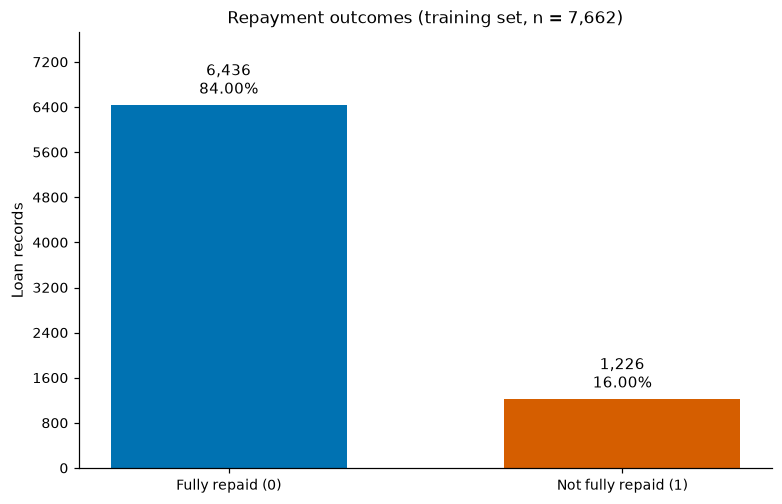

In [24]:
fig, ax = plt.subplots(figsize=(7.2, 4.6), layout="constrained")
bars = ax.bar(
    [OUTCOME_LABELS[0], OUTCOME_LABELS[1]], eda_target_counts.to_numpy(),
    color=[OUTCOME_COLORS[0], OUTCOME_COLORS[1]], width=0.6,
)
for bar, count in zip(bars, eda_target_counts):
    ax.text(
        bar.get_x() + bar.get_width() / 2, count + 110,
        f"{count:,}\n{count / len(eda_data):.2%}",
        ha="center", va="bottom",
    )
ax.set_ylim(0, eda_target_counts.max() * 1.2)
ax.set_ylabel("Loan records")
ax.set_title(f"Repayment outcomes (training set, n = {len(eda_data):,})")
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(axis="y", alpha=0.22)
ax.set_axisbelow(True)
export_figure(fig, "eda_01_outcomes.png")


### 5.3 Four-Factor Distributions

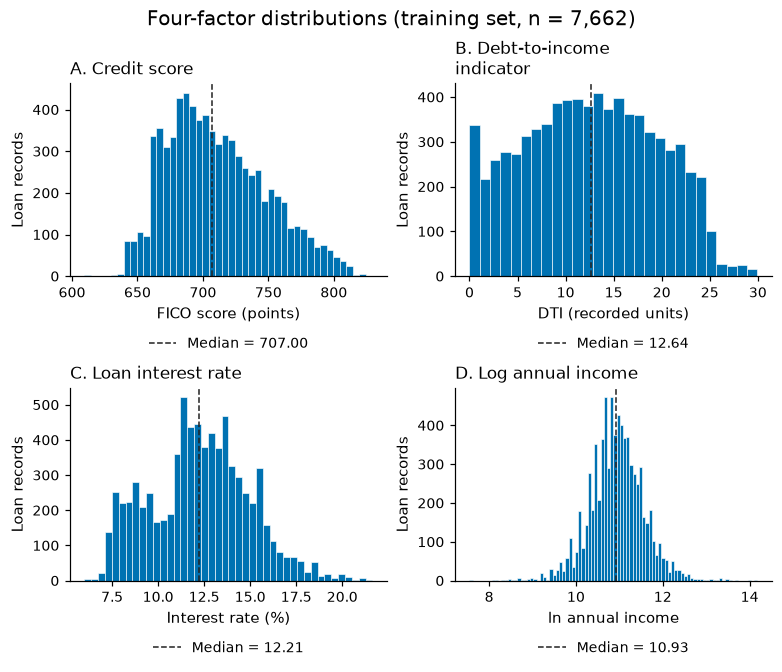

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 7.3), layout="constrained")
panel_titles = ["A. Credit score", "B. Debt-to-income indicator",
                "C. Loan interest rate", "D. Log annual income"]
for ax, field, panel_title in zip(axes.flat, FOCUS_FACTORS, panel_titles):
    values = eda_plot[field]
    bins = (
        np.arange(values.min() - 2.5, values.max() + 5, 5)
        if field == "fico" else np.histogram_bin_edges(values, bins="fd")
    )
    histogram_edges[field] = bins
    ax.hist(values, bins=bins, color="#0072B2", edgecolor="white", linewidth=0.4)
    ax.axvline(values.median(), color="#222222", linestyle="--", linewidth=1,
               label=f"Median = {values.median():.2f}")
    ax.set_title(panel_title, loc="left")
    ax.set_xlabel(FACTOR_LABELS[field])
    ax.set_ylabel("Loan records")
    ax.legend(frameon=False, fontsize=9)
    ax.grid(axis="y", alpha=0.18)
    ax.set_axisbelow(True)
fig.suptitle(f"Four-factor distributions (training set, n = {len(eda_data):,})", fontsize=13)
export_figure(fig, "eda_02_factor_distributions.png")


### 5.4 Factor Distributions by Outcome

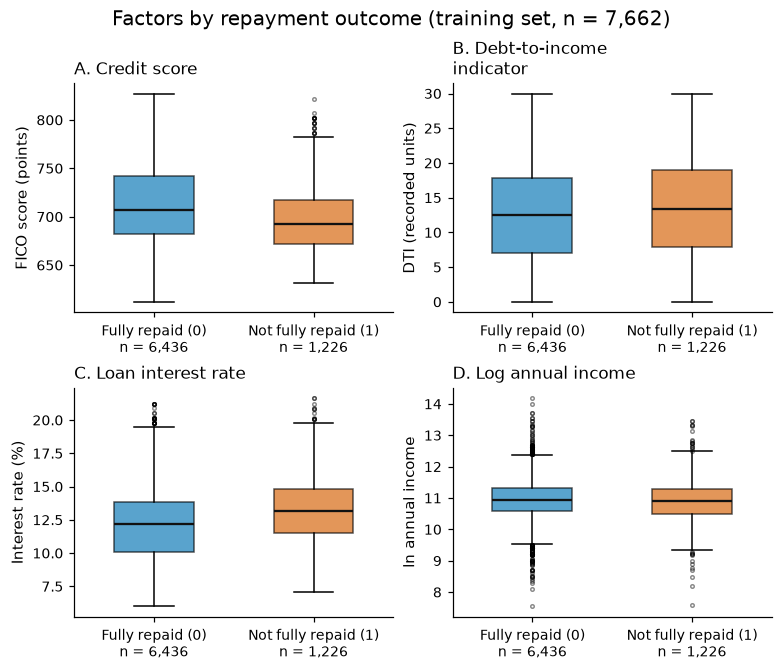

In [26]:
group_tick_labels = [
    f"{OUTCOME_LABELS[outcome]}\nn = {eda_target_counts[outcome]:,}"
    for outcome in [0, 1]
]
fig, axes = plt.subplots(2, 2, figsize=(10.5, 7.7), layout="constrained")
for ax, field, panel_title in zip(axes.flat, FOCUS_FACTORS, panel_titles):
    group_values = [
        eda_plot.loc[eda_data[TARGET].eq(outcome), field].to_numpy()
        for outcome in [0, 1]
    ]
    boxes = ax.boxplot(
        group_values, tick_labels=group_tick_labels, patch_artist=True, whis=1.5,
        widths=0.5,
        medianprops={"color": "#111111", "linewidth": 1.5},
        flierprops={"marker": "o", "markersize": 2.3, "alpha": 0.45},
    )
    for outcome, box in zip([0, 1], boxes["boxes"]):
        box.set_facecolor(OUTCOME_COLORS[outcome])
        box.set_alpha(0.65)
    ax.set_ylabel(FACTOR_LABELS[field])
    ax.set_title(panel_title, loc="left")
    ax.grid(axis="y", alpha=0.18)
    ax.set_axisbelow(True)
fig.suptitle(f"Factors by repayment outcome (training set, n = {len(eda_data):,})", fontsize=13)
export_figure(fig, "eda_03_factors_by_outcome.png")


### 5.5 Pairwise Relationships

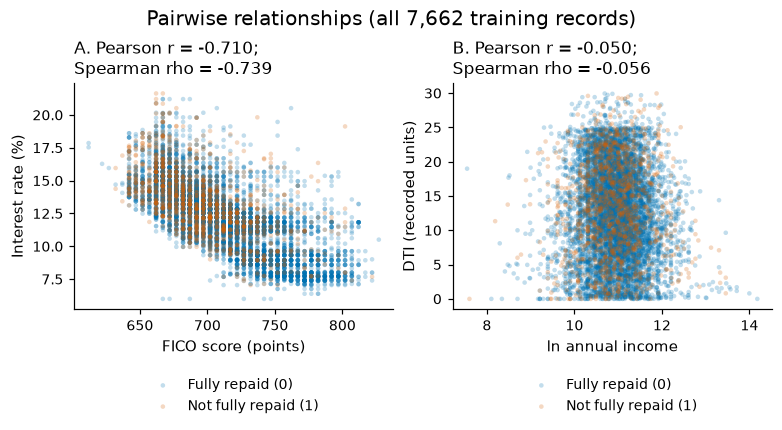

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 5.1), layout="constrained")
scatter_pairs = [("fico", "int.rate"), ("log.annual.inc", "dti")]
for ax, (left, right), panel in zip(axes, scatter_pairs, ["A", "B"]):
    for outcome in [0, 1]:
        mask = eda_data[TARGET].eq(outcome)
        ax.scatter(
            eda_plot.loc[mask, left], eda_plot.loc[mask, right],
            s=9, alpha=0.24, color=OUTCOME_COLORS[outcome],
            edgecolors="none", label=OUTCOME_LABELS[outcome],
        )
    ax.set_xlabel(FACTOR_LABELS[left])
    ax.set_ylabel(FACTOR_LABELS[right])
    ax.set_title(
        f"{panel}. Pearson r = {pearson_corr.at[left, right]:.3f}; "
        f"Spearman rho = {spearman_corr.at[left, right]:.3f}", loc="left",
    )
    ax.legend(fontsize=9, framealpha=0.9, loc="upper right")
    ax.grid(alpha=0.16)
    ax.set_axisbelow(True)
fig.suptitle(f"Pairwise relationships (all {len(eda_data):,} training records)", fontsize=13)
export_figure(fig, "eda_04_pairwise_relationships.png")


### 5.6 Numeric Correlation Structure

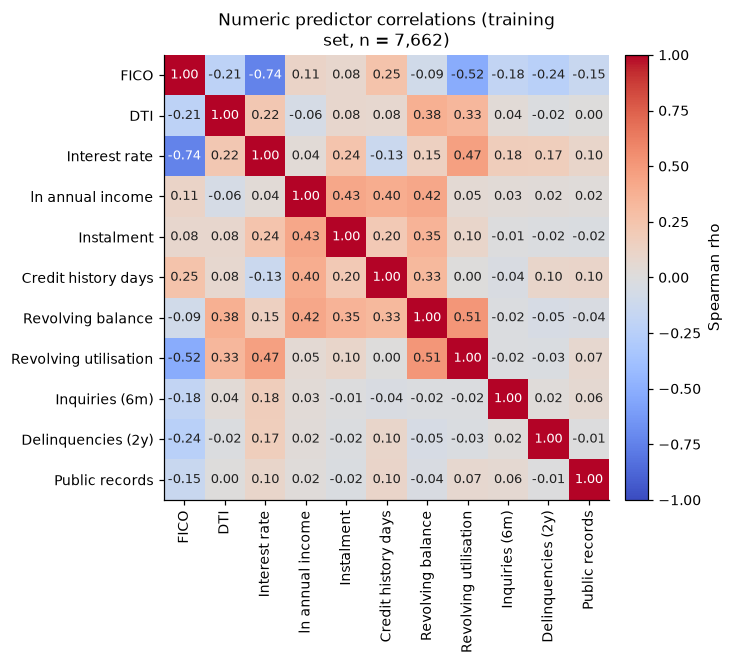

In [28]:
correlation_fields = FOCUS_FACTORS + [
    field for field in numeric_predictors if field not in FOCUS_FACTORS
]
correlation_labels = {
    "fico": "FICO", "dti": "DTI", "int.rate": "Interest rate",
    "log.annual.inc": "ln annual income", "installment": "Instalment",
    "days.with.cr.line": "Credit history days", "revol.bal": "Revolving balance",
    "revol.util": "Revolving utilisation", "inq.last.6mths": "Inquiries (6m)",
    "delinq.2yrs": "Delinquencies (2y)", "pub.rec": "Public records",
}
correlation_matrix = spearman_corr.loc[correlation_fields, correlation_fields]
fig, ax = plt.subplots(figsize=(10.4, 8.8), layout="constrained")
heatmap = ax.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)
labels = [correlation_labels[field] for field in correlation_fields]
ax.set_xticks(range(len(labels)), labels, rotation=90, ha="right", va="center", rotation_mode="anchor")
ax.set_yticks(range(len(labels)), labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        value = correlation_matrix.iat[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8.5,
                color="white" if abs(value) >= 0.6 else "#222222")
colorbar = fig.colorbar(heatmap, ax=ax, fraction=0.045, pad=0.025)
colorbar.set_label("Spearman rho")
ax.set_title(f"Numeric predictor correlations (training set, n = {len(eda_data):,})", pad=14)
export_figure(fig, "eda_05_numeric_correlations.png")


### 5.7 Within-Purpose Outcome Rates

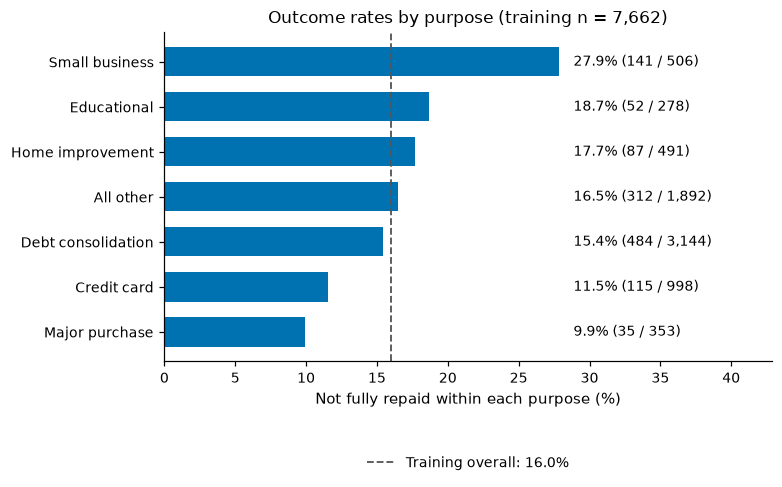

,Records,Positive_records,Positive rate (%)
purpose,,,
major_purchase,353,35,9.92
credit_card,998,115,11.52
debt_consolidation,3144,484,15.39
all_other,1892,312,16.49
home_improvement,491,87,17.72
educational,278,52,18.71
small_business,506,141,27.87


In [29]:
purpose_order = purpose_eda.sort_values("Positive rate (%)")
fig, ax = plt.subplots(figsize=(9.4, 5.8), layout="constrained")
purpose_labels = purpose_order.index.str.replace("_", " ").str.capitalize()
bars = ax.barh(
    purpose_labels, purpose_order["Positive rate (%)"], color="#0072B2", height=0.65,
)
for bar, (_, row) in zip(bars, purpose_order.iterrows()):
    ax.text(
        purpose_order["Positive rate (%)"].max() + 1.0, bar.get_y() + bar.get_height() / 2,
        f"{row['Positive rate (%)']:.1f}% "
        f"({int(row['Positive_records']):,} / {int(row['Records']):,})",
        va="center", fontsize=9,
        bbox={"facecolor": "white", "edgecolor": "none", "pad": 0.2},
    )
overall_rate = eda_data[TARGET].mean() * 100
ax.axvline(overall_rate, color="#555555", linestyle="--", linewidth=1.2,
           label=f"Training overall: {overall_rate:.1f}%")
ax.set_xlim(0, purpose_order["Positive rate (%)"].max() + 15)
ax.set_xlabel("Not fully repaid within each purpose (%)")
ax.set_title(f"Outcome rates by purpose (training n = {len(eda_data):,})")
ax.legend(loc="lower right", frameon=False, fontsize=9)
ax.grid(axis="x", alpha=0.18)
ax.set_axisbelow(True)
export_figure(fig, "eda_06_purpose_rates.png")
display(purpose_order[["Records", "Positive_records", "Positive rate (%)"]].round(2))


### 5.8 Supplementary Distribution Review

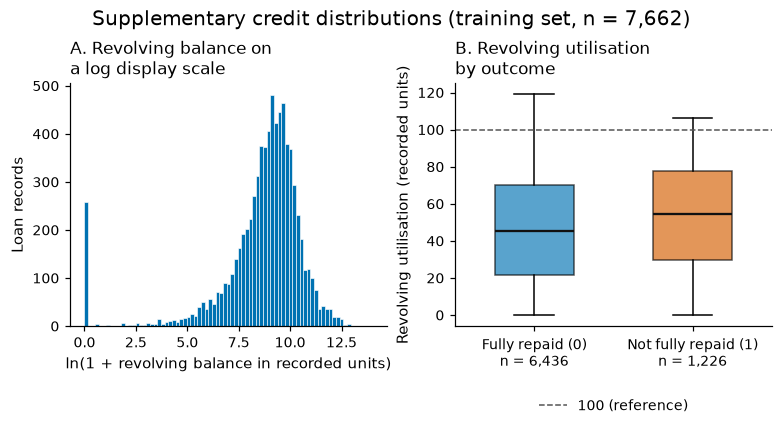

,Training result
Revolving balance median,8.653000e+03
Revolving balance mean,1.705783e+04
Revolving balance maximum,1.207359e+06
Utilisation above 100 (records retained),2.200000e+01


In [30]:
fig, axes = plt.subplots(1, 2, figsize=(11.4, 5.2), layout="constrained")
balance_log_display = np.log1p(eda_data["revol.bal"])
axes[0].hist(
    balance_log_display, bins=np.histogram_bin_edges(balance_log_display, bins="fd"),
    color="#0072B2", edgecolor="white", linewidth=0.4,
)
axes[0].set_title("A. Revolving balance on a log display scale", loc="left")
axes[0].set_xlabel("ln(1 + revolving balance in recorded units)")
axes[0].set_ylabel("Loan records")
axes[0].grid(axis="y", alpha=0.18)
utilisation_values = [
    eda_data.loc[eda_data[TARGET].eq(outcome), "revol.util"].to_numpy()
    for outcome in [0, 1]
]
boxes = axes[1].boxplot(
    utilisation_values, tick_labels=group_tick_labels, patch_artist=True, whis=1.5,
    widths=0.5, medianprops={"color": "#111111", "linewidth": 1.5},
    flierprops={"marker": "o", "markersize": 2.3, "alpha": 0.45},
)
for outcome, box in zip([0, 1], boxes["boxes"]):
    box.set_facecolor(OUTCOME_COLORS[outcome])
    box.set_alpha(0.65)
axes[1].axhline(100, color="#555555", linestyle="--", linewidth=1,
               label="100 (reference)")
axes[1].set_ylabel("Revolving utilisation (recorded units)")
axes[1].set_title("B. Revolving utilisation by outcome", loc="left")
axes[1].legend(frameon=False, fontsize=9, loc="upper left")
axes[1].grid(axis="y", alpha=0.18)
for ax in axes:
    ax.set_axisbelow(True)
fig.suptitle(f"Supplementary credit distributions (training set, n = {len(eda_data):,})", fontsize=13)
export_figure(fig, "eda_07_credit_distribution_review.png")
display(pd.Series({
    "Revolving balance median": eda_data["revol.bal"].median(),
    "Revolving balance mean": eda_data["revol.bal"].mean(),
    "Revolving balance maximum": eda_data["revol.bal"].max(),
    "Utilisation above 100 (records retained)": eda_data["revol.util"].gt(100).sum(),
}, name="Training result").to_frame())


### 5.9 EDA Validation

In [31]:
assert len(eda_data) == 7662
assert set(eda_data["record_id"]) == set(train_ids)
assert set(eda_data["record_id"]).isdisjoint(test_ids)
assert eda_target_counts.to_dict() == {0: 6436, 1: 1226}
assert purpose_eda["Records"].sum() == len(eda_data)
assert purpose_eda["Positive_records"].sum() == int(y_train.sum())
np.testing.assert_allclose(
    purpose_eda["Positive rate (%)"],
    purpose_eda["Positive_records"] / purpose_eda["Records"] * 100,
)
for field, bins in histogram_edges.items():
    assert int(np.histogram(eda_plot[field], bins=bins)[0].sum()) == len(eda_data)
assert correlation_matrix.columns.tolist() == correlation_matrix.index.tolist() == correlation_fields
assert "record_id" not in correlation_fields and TARGET not in correlation_fields
np.testing.assert_allclose(correlation_matrix, correlation_matrix.T)
np.testing.assert_allclose(np.diag(correlation_matrix), 1)
assert np.isfinite(correlation_matrix.to_numpy()).all()
assert len(figure_paths) == 7 and len(set(figure_paths)) == 7
assert all(path.is_file() and path.stat().st_size > 10000 for path in figure_paths)
pd.testing.assert_frame_equal(eda_data, train_data, check_exact=True)
np.testing.assert_array_equal(eda_plot["int.rate"], eda_data["int.rate"] * 100)
assert hashlib.sha256(DB_PATH.read_bytes()).hexdigest() == eda_database_sha256
assert hashlib.sha256(SOURCE_PATH.read_bytes()).hexdigest() == source_sha256

print("EDA validation passed. All seven figures use training records only.")
print("Histogram counts, within-purpose denominators and correlation fields were verified.")
print("Visual display transformations did not alter source or database values.")


EDA validation passed. All seven figures use training records only.
Histogram counts, within-purpose denominators and correlation fields were verified.
Visual display transformations did not alter source or database values.


## 6. Statistical Factor Analysis

### 6.1 Training Scope and Group Diagnostics

In [32]:
import scipy
from scipy import stats

ALPHA = 0.05
BOOTSTRAP_RESAMPLES = 4000
BOOTSTRAP_BATCH = 32
statistics_database_sha256 = hashlib.sha256(DB_PATH.read_bytes()).hexdigest()
statistics_data = eda_data[["record_id", TARGET] + FOCUS_FACTORS].copy()
statistical_groups = {}
diagnostic_rows = []
for field in FOCUS_FACTORS:
    statistical_groups[field] = {}
    for outcome in [0, 1]:
        values = statistics_data.loc[statistics_data[TARGET].eq(outcome), field].to_numpy()
        assert np.isfinite(values).all() and len(values) > 1
        statistical_groups[field][outcome] = values
        display_values = pd.Series(values * 100 if field == "int.rate" else values)
        diagnostic_rows.append({
            "Factor": field, "Outcome": outcome, "N": len(values),
            "Unique values": display_values.nunique(),
            "SD": display_values.std(ddof=1), "Skewness": display_values.skew(),
            "Q1": display_values.quantile(0.25), "Median": display_values.median(),
            "Q3": display_values.quantile(0.75),
            "IQR": display_values.quantile(0.75) - display_values.quantile(0.25),
        })
group_diagnostics = pd.DataFrame(diagnostic_rows).set_index(["Factor", "Outcome"])
print(f"SciPy {scipy.__version__}; training records only: {len(statistics_data):,}.")
display(group_diagnostics.round(4))

SciPy 1.18.1; training records only: 7,662.


N  Unique values       SD  Skewness        Q1  \
Factor         Outcome                                                     
fico           0        6436             43  38.2324    0.4296  682.0000   
               1        1226             37  33.5564    0.6536  672.0000   
dti            0        6436           2335   6.8582    0.0346    7.0700   
               1        1226            948   7.0393   -0.0131    7.9125   
int.rate       0        6436            238   2.6570    0.1463   10.0800   
               1        1226            219   2.5482    0.2755   11.4800   
log.annual.inc 0        6436           1484   0.6041   -0.0003   10.5910   
               1        1226            447   0.6659    0.0497   10.4913   

                          Median        Q3      IQR  
Factor         Outcome                               
fico           0        707.0000  742.0000  60.0000  
               1        692.0000  717.0000  45.0000  
dti            0         12.5100   17.8425  10.7725  
               1         13.3550   18.9300  11.0175  
int.rate       0         12.1800   13.8700   3.7900  
               1         13.1600   14.8200   3.3400  
log.annual.inc 0         10.9331   11.3096   0.7185  
               1         10.8967   11.2898   0.7985

### 6.2 Two-Sided Mann-Whitney Tests and Holm Adjustment

In [33]:
def holm_adjust(p_values):
    p_values = np.asarray(p_values, dtype=float)
    assert p_values.ndim == 1 and p_values.size > 0
    assert np.isfinite(p_values).all() and ((p_values >= 0) & (p_values <= 1)).all()
    order = np.argsort(p_values)
    adjusted = np.empty_like(p_values)
    adjusted[order] = np.minimum(
        1, np.maximum.accumulate(p_values[order] * np.arange(len(p_values), 0, -1))
    )
    return adjusted


def rank_biserial(x, y, axis=-1):
    u = stats.mannwhitneyu(
        x, y, axis=axis, alternative="two-sided", method="asymptotic",
        use_continuity=True, nan_policy="raise",
    ).statistic
    return 2 * u / (x.shape[axis] * y.shape[axis]) - 1


statistical_rows = []
for field in FOCUS_FACTORS:
    positive = statistical_groups[field][1]
    negative = statistical_groups[field][0]
    result = stats.mannwhitneyu(
        positive, negative, alternative="two-sided", method="asymptotic",
        use_continuity=True, nan_policy="raise",
    )
    pair_count = len(positive) * len(negative)
    statistical_rows.append({
        "Factor": field, "N (class 1)": len(positive), "N (class 0)": len(negative),
        "U (class 1)": result.statistic, "p (raw)": result.pvalue,
        "Rank-biserial r": 2 * result.statistic / pair_count - 1,
        "A (higher in class 1)": result.statistic / pair_count,
    })
statistical_results = pd.DataFrame(statistical_rows).set_index("Factor")
statistical_results["p (Holm)"] = holm_adjust(statistical_results["p (raw)"].to_numpy())
statistical_results["Reject equal distributions (Holm)"] = statistical_results["p (Holm)"] < ALPHA
# U uses class 1 as the first sample. Ties contribute half a pair to A.
display(statistical_results.style.format({
    "U (class 1)": "{:,.1f}", "p (raw)": "{:.3e}", "p (Holm)": "{:.3e}",
    "Rank-biserial r": "{:.4f}", "A (higher in class 1)": "{:.4f}",
}))

,N (class 1),N (class 0),U (class 1),p (raw),Rank-biserial r,A (higher in class 1),p (Holm),Reject equal distributions (Holm)
Factor,,,,,,,,
fico,1226,6436,"3,052,669.0",2.550e-36,-0.2262,0.3869,7.650e-36,True
dti,1226,6436,"4,182,234.5",8.430e-04,0.0601,0.5300,1.686e-03,True
int.rate,1226,6436,"4,882,322.0",8.497e-40,0.2375,0.6188,3.399e-39,True
log.annual.inc,1226,6436,"3,757,717.0",8.234e-03,-0.0475,0.4762,8.234e-03,True


### 6.3 Pointwise Bootstrap Intervals for Rank Effects

In [34]:
bootstrap_distributions = {}
for index, field in enumerate(FOCUS_FACTORS):
    positive = statistical_groups[field][1]
    negative = statistical_groups[field][0]
    interval = stats.bootstrap(
        (positive, negative), rank_biserial,
        n_resamples=BOOTSTRAP_RESAMPLES, batch=BOOTSTRAP_BATCH,
        vectorized=True, paired=False, confidence_level=0.95,
        alternative="two-sided", method="basic",
        rng=np.random.default_rng(RANDOM_STATE + index),
    )
    bootstrap_distributions[field] = interval.bootstrap_distribution
    statistical_results.loc[field, "CI lower"] = interval.confidence_interval.low
    statistical_results.loc[field, "CI upper"] = interval.confidence_interval.high
    statistical_results.loc[field, "Bootstrap SE"] = interval.standard_error
    statistical_results.loc[field, "Bootstrap seed"] = RANDOM_STATE + index
statistical_results["Bootstrap seed"] = statistical_results["Bootstrap seed"].astype(int)
display(statistical_results.style.format({
    "U (class 1)": "{:,.1f}", "p (raw)": "{:.3e}", "p (Holm)": "{:.3e}",
    "Rank-biserial r": "{:.4f}", "A (higher in class 1)": "{:.4f}",
    "CI lower": "{:.4f}", "CI upper": "{:.4f}", "Bootstrap SE": "{:.4f}",
}))

,N (class 1),N (class 0),U (class 1),p (raw),Rank-biserial r,A (higher in class 1),p (Holm),Reject equal distributions (Holm),CI lower,CI upper,Bootstrap SE,Bootstrap seed
Factor,,,,,,,,,,,,
fico,1226,6436,"3,052,669.0",2.550e-36,-0.2262,0.3869,7.650e-36,True,-0.2599,-0.1919,0.0170,42
dti,1226,6436,"4,182,234.5",8.430e-04,0.0601,0.5300,1.686e-03,True,0.0245,0.0956,0.0180,43
int.rate,1226,6436,"4,882,322.0",8.497e-40,0.2375,0.6188,3.399e-39,True,0.2047,0.2698,0.0165,44
log.annual.inc,1226,6436,"3,757,717.0",8.234e-03,-0.0475,0.4762,8.234e-03,True,-0.0836,-0.0115,0.0184,45


### 6.4 Unadjusted Rank Effects and Uncertainty

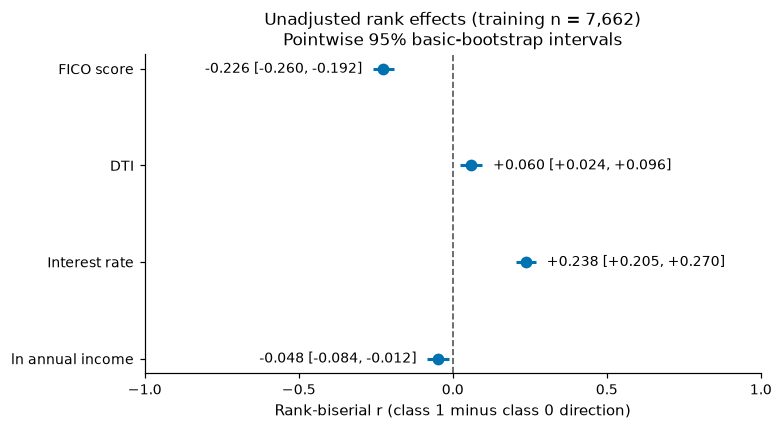

In [35]:
effect_labels = ["FICO score", "DTI", "Interest rate", "ln annual income"]
fig, ax = plt.subplots(figsize=(9.4, 4.8), layout="constrained")
for position, field in enumerate(FOCUS_FACTORS):
    row = statistical_results.loc[field]
    ax.hlines(position, row["CI lower"], row["CI upper"], color="#0072B2", linewidth=2)
    ax.scatter(row["Rank-biserial r"], position, color="#0072B2", s=45, zorder=3)
    negative_effect = row["Rank-biserial r"] < 0
    label_x = row["CI lower"] - 0.035 if negative_effect else row["CI upper"] + 0.035
    ax.text(label_x, position,
            f"{row['Rank-biserial r']:+.3f} "
            f"[{row['CI lower']:+.3f}, {row['CI upper']:+.3f}]",
            va="center", ha="right" if negative_effect else "left", fontsize=9,
            bbox={"facecolor": "white", "edgecolor": "none", "pad": 0.2})
ax.axvline(0, color="#555555", linestyle="--", linewidth=1.1)
ax.set_yticks(range(len(FOCUS_FACTORS)), effect_labels)
ax.invert_yaxis()
ax.set_xlim(-1, 1)
ax.set_xticks([-1, -0.5, 0, 0.5, 1])
ax.set_xlabel("Rank-biserial r (class 1 minus class 0 direction)")
ax.set_title(
    f"Unadjusted rank effects (training n = {len(statistics_data):,})\n"
    "Pointwise 95% basic-bootstrap intervals"
)
ax.grid(axis="x", alpha=0.18)
ax.set_axisbelow(True)
export_figure(fig, "stats_08_factor_effects.png")
statistical_figure_path = figure_paths[-1]

### 6.5 Statistical Calculation and Scope Checks

In [36]:
# A tied synthetic example independently checks the signed rank effect.
check_positive = np.array([1.0, 2.0, 2.0])
check_negative = np.array([2.0, 3.0])
direct_effect = np.sign(check_positive[:, None] - check_negative[None, :]).mean()
np.testing.assert_allclose(rank_biserial(check_positive, check_negative), direct_effect)
np.testing.assert_allclose(rank_biserial(check_negative, check_positive), -direct_effect)
np.testing.assert_allclose(rank_biserial(check_positive, check_positive), 0)
np.testing.assert_allclose(rank_biserial(np.array([3., 4.]), np.array([1., 2.])), 1)
np.testing.assert_allclose(holm_adjust([0.2, 0.01, 0.04, 0.03]), [0.2, 0.04, 0.09, 0.09])
np.testing.assert_allclose(holm_adjust([0.7]), [0.7])

assert statistical_results.index.tolist() == FOCUS_FACTORS
assert set(statistics_data["record_id"]) == set(train_ids)
assert set(statistics_data["record_id"]).isdisjoint(test_ids)
pd.testing.assert_frame_equal(statistics_data, train_data[["record_id", TARGET] + FOCUS_FACTORS])
for field in FOCUS_FACTORS:
    positive = statistical_groups[field][1]
    negative = statistical_groups[field][0]
    row = statistical_results.loc[field]
    assert len(positive) == 1226 and len(negative) == 6436
    # Sorted pair counts verify U independently, including ties.
    sorted_negative = np.sort(negative)
    lower = np.searchsorted(sorted_negative, positive, side="left")
    upper = np.searchsorted(sorted_negative, positive, side="right")
    direct_u = (lower + 0.5 * (upper - lower)).sum()
    np.testing.assert_allclose(row["U (class 1)"], direct_u)
    np.testing.assert_allclose(row["Rank-biserial r"], rank_biserial(positive, negative))
    np.testing.assert_allclose(row["Rank-biserial r"], 2 * row["A (higher in class 1)"] - 1)
    distribution = bootstrap_distributions[field]
    assert distribution.shape == (BOOTSTRAP_RESAMPLES,)
    assert np.isfinite(distribution).all() and (np.abs(distribution) <= 1).all()
    np.testing.assert_allclose(
        [row["CI lower"], row["CI upper"]],
        2 * row["Rank-biserial r"] - np.quantile(distribution, [0.975, 0.025]),
    )
    assert -1 <= row["CI lower"] < row["Rank-biserial r"] < row["CI upper"] <= 1
assert (statistical_results["p (Holm)"] >= statistical_results["p (raw)"]).all()
assert statistical_results[["p (raw)", "p (Holm)"]].ge(0).all().all()
assert statistical_results[["p (raw)", "p (Holm)"]].le(1).all().all()
np.testing.assert_allclose(
    rank_biserial(statistical_groups["int.rate"][1] * 100, statistical_groups["int.rate"][0] * 100),
    statistical_results.loc["int.rate", "Rank-biserial r"],
)
assert statistical_figure_path.is_file() and statistical_figure_path.stat().st_size > 10000
assert hashlib.sha256(DB_PATH.read_bytes()).hexdigest() == statistics_database_sha256
assert hashlib.sha256(SOURCE_PATH.read_bytes()).hexdigest() == source_sha256
assert all(not hasattr(pipeline["columns"], "transformers_")
           for pipeline in preprocessing_pipelines.values())
print("Statistical validation passed: four training-only comparisons, tied pair counts and Holm checks.")
print("Four pointwise bootstrap intervals and the effect figure were verified.")
print("Source/database values are unchanged. No classification model was fitted.")

Statistical validation passed: four training-only comparisons, tied pair counts and Holm checks.
Four pointwise bootstrap intervals and the effect figure were verified.
Source/database values are unchanged. No classification model was fitted.


## 7. Initial AP-Focused Model Development and Selection

### 7.1 Candidate Pipelines and Bounded Parameter Grids

In [37]:
import json
import warnings
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, ParameterGrid, cross_val_predict
from sklearn.metrics import (
    average_precision_score, roc_auc_score, balanced_accuracy_score, accuracy_score,
)
from sklearn.exceptions import ConvergenceWarning

models_database_sha256 = hashlib.sha256(DB_PATH.read_bytes()).hexdigest()
model_specs = {
    "Majority baseline": {
        "preprocessing": "unscaled", "classifier": DummyClassifier(strategy="prior"),
        "grid": {},
    },
    "Logistic Regression": {
        "preprocessing": "scaled",
        "classifier": LogisticRegression(solver="lbfgs", l1_ratio=0.0, max_iter=4000),
        "grid": {"classifier__C": [0.1, 1.0], "classifier__class_weight": [None, "balanced"]},
    },
    "Decision Tree": {
        "preprocessing": "unscaled",
        "classifier": DecisionTreeClassifier(min_samples_leaf=50, random_state=RANDOM_STATE),
        "grid": {"classifier__max_depth": [3, 6], "classifier__class_weight": [None, "balanced"]},
    },
    "Random Forest": {
        "preprocessing": "unscaled",
        "classifier": RandomForestClassifier(
            n_estimators=200, min_samples_leaf=20, max_features="sqrt",
            bootstrap=True, random_state=RANDOM_STATE, n_jobs=2,
        ),
        "grid": {"classifier__max_depth": [8, None], "classifier__class_weight": [None, "balanced"]},
    },
}
model_templates = {
    name: Pipeline([
        ("preprocess", clone(preprocessing_pipelines[spec["preprocessing"]])),
        ("classifier", clone(spec["classifier"])),
    ])
    for name, spec in model_specs.items()
}
THRESHOLD_GRID = np.round(np.arange(0.05, 1.0, 0.05), 2)
THRESHOLD_METRIC = "positive-class F1"
DEFAULT_THRESHOLD = 0.5
candidate_plan = pd.DataFrame([
    {"Model": name, "Preprocessing": spec["preprocessing"],
     "Configurations": len(ParameterGrid(spec["grid"])), "Grid": spec["grid"]}
    for name, spec in model_specs.items()
]).set_index("Model")
assert candidate_plan["Configurations"].sum() == 13
print("Selection: highest mean 10-fold AP; exact ties use candidate order.")
print("Threshold: highest pooled out-of-fold F1 on the fixed grid; ties use the higher threshold.")
display(candidate_plan)

Selection: highest mean 10-fold AP; exact ties use candidate order.
Threshold: highest pooled out-of-fold F1 on the fixed grid; ties use the higher threshold.


,Preprocessing,Configurations,Grid
Model,,,
Majority baseline,unscaled,1,{}
Logistic Regression,scaled,4,"{'classifier__C': [0.1, 1.0], 'classifier__cla..."
Decision Tree,unscaled,4,"{'classifier__max_depth': [3, 6], 'classifier_..."
Random Forest,unscaled,4,"{'classifier__max_depth': [8, None], 'classifi..."


### 7.2 Identical-Fold Grid Search

In [38]:
model_searches = {}
model_best_parameters = {}
comparison_rows = []
configuration_frames = []
fold_score_rows = []
for name, template in model_templates.items():
    search = GridSearchCV(
        template, model_specs[name]["grid"], scoring=scoring,
        refit=False, cv=cv_splits, n_jobs=1,
        return_train_score=True, error_score="raise",
    )
    with warnings.catch_warnings():
        warnings.simplefilter("error", ConvergenceWarning)
        search.fit(X_train, y_train)
    model_searches[name] = search
    results = search.cv_results_
    best_index = int(np.argmax(results[f"mean_test_{PRIMARY_METRIC}"]))
    model_best_parameters[name] = results["params"][best_index]
    row = {"Model": name, "Configurations": len(results["params"]),
           "Mean fit seconds": float(results["mean_fit_time"][best_index]),
           "Train AP mean": float(results["mean_train_average_precision"][best_index])}
    for metric in scoring:
        row[f"{metric} mean"] = float(results[f"mean_test_{metric}"][best_index])
        row[f"{metric} SD"] = float(results[f"std_test_{metric}"][best_index])
    comparison_rows.append(row)
    configuration_frames.append(pd.DataFrame({
        "Model": name, "Parameters": results["params"],
        "Validation AP mean": results["mean_test_average_precision"],
        "Validation AP SD": results["std_test_average_precision"],
        "Training AP mean": results["mean_train_average_precision"],
    }))
    for fold in range(N_FOLDS):
        fold_score_rows.append({
            "Model": name, "Fold": fold + 1,
            **{metric: float(results[f"split{fold}_test_{metric}"][best_index])
               for metric in scoring},
        })
    print(f"{name}: {len(results['params'])} configurations; "
          f"selected validation AP = {row['average_precision mean']:.4f}.")
model_comparison = pd.DataFrame(comparison_rows).set_index("Model")
configuration_results = pd.concat(configuration_frames, ignore_index=True)
selected_fold_scores = pd.DataFrame(fold_score_rows)
selected_model_name = model_comparison["average_precision mean"].idxmax()
selected_template = clone(model_templates[selected_model_name]).set_params(
    **model_best_parameters[selected_model_name]
)
display(configuration_results)
display(model_comparison.round(4))
display(pd.Series(model_best_parameters, name="Best parameters").to_frame())
print(f"Selected family by mean AP: {selected_model_name}")

Majority baseline: 1 configurations; selected validation AP = 0.1600.


Logistic Regression: 4 configurations; selected validation AP = 0.2970.


Decision Tree: 4 configurations; selected validation AP = 0.2362.


Random Forest: 4 configurations; selected validation AP = 0.2873.


,Model,Parameters,Validation AP mean,Validation AP SD,Training AP mean
0,Majority baseline,{},0.160010,0.000610,0.160010
1,Logistic Regression,"{'classifier__C': 0.1, 'classifier__class_weig...",0.295793,0.033924,0.292197
2,Logistic Regression,"{'classifier__C': 0.1, 'classifier__class_weig...",0.296063,0.035257,0.291073
3,Logistic Regression,"{'classifier__C': 1.0, 'classifier__class_weig...",0.296109,0.033821,0.292870
4,Logistic Regression,"{'classifier__C': 1.0, 'classifier__class_weig...",0.296998,0.035126,0.291640
5,Decision Tree,"{'classifier__class_weight': None, 'classifier...",0.231423,0.016941,0.239557
6,Decision Tree,"{'classifier__class_weight': None, 'classifier...",0.235533,0.014325,0.294616
7,Decision Tree,"{'classifier__class_weight': 'balanced', 'clas...",0.218721,0.012077,0.233344
8,Decision Tree,"{'classifier__class_weight': 'balanced', 'clas...",0.236206,0.018144,0.292413
9,Random Forest,"{'classifier__class_weight': None, 'classifier...",0.287309,0.028913,0.455906


,Configurations,Mean fit seconds,Train AP mean,average_precision mean,average_precision SD,roc_auc mean,roc_auc SD,precision mean,...,recall mean,recall SD,f1 mean,f1 SD,balanced_accuracy mean,balanced_accuracy SD,accuracy mean,accuracy SD
Model,,,,,,,,,,,,,,,,,
Majority baseline,1,0.0063,0.1600,0.1600,0.0006,0.5000,0.0000,0.0000,...,0.0000,0.0000,0.0000,0.0000,0.5000,0.0000,0.84,0.0006
Logistic Regression,4,0.0175,0.2916,0.2970,0.0351,0.6780,0.0240,0.2454,...,0.6021,0.0514,0.3485,0.0254,0.6247,0.0274,0.64,0.0175
Decision Tree,4,0.0249,0.2924,0.2362,0.0181,0.6342,0.0218,0.2308,...,0.5318,0.0646,0.3208,0.0211,0.5962,0.0212,0.64,0.0366
Random Forest,4,0.5223,0.4559,0.2873,0.0289,0.6735,0.0263,0.0000,...,0.0000,0.0000,0.0000,0.0000,0.5000,0.0000,0.84,0.0006


,Best parameters
Majority baseline,{}
Logistic Regression,"{'classifier__C': 1.0, 'classifier__class_weig..."
Decision Tree,"{'classifier__class_weight': 'balanced', 'clas..."
Random Forest,"{'classifier__class_weight': None, 'classifier..."


Selected family by mean AP: Logistic Regression


### 7.3 Training and Validation AP Comparison

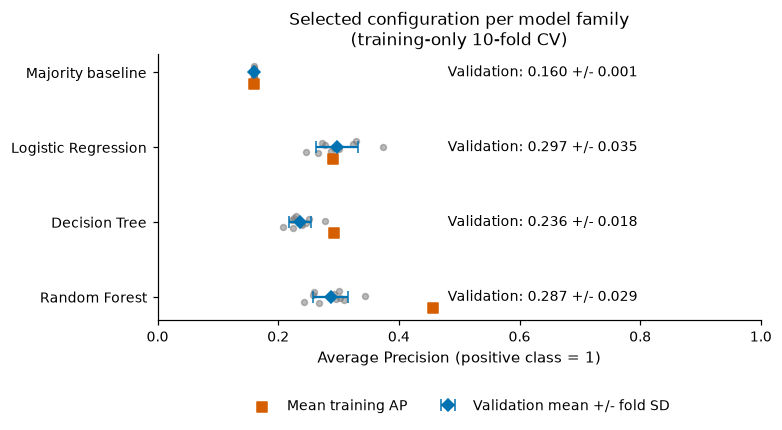

In [39]:
model_names = list(model_specs)
positions = np.arange(len(model_names))
fig, ax = plt.subplots(figsize=(10.4, 5.2), layout="constrained")
for position, name in enumerate(model_names):
    scores = selected_fold_scores.loc[selected_fold_scores["Model"].eq(name), "average_precision"]
    ax.scatter(scores, position + np.linspace(-0.08, 0.08, N_FOLDS),
               color="#777777", alpha=0.5, s=15, zorder=2)
validation_means = model_comparison.loc[model_names, "average_precision mean"]
validation_sd = model_comparison.loc[model_names, "average_precision SD"]
training_means = model_comparison.loc[model_names, "Train AP mean"]
ax.errorbar(validation_means, positions, xerr=validation_sd,
            fmt="D", color="#0072B2", capsize=4, markersize=6,
            label="Validation mean +/- fold SD", zorder=3)
ax.scatter(training_means, positions + 0.15, marker="s", color="#D55E00",
           s=40, label="Mean training AP", zorder=3)
annotation_x = max(training_means.max(), selected_fold_scores["average_precision"].max()) + 0.025
for position, name in enumerate(model_names):
    row = model_comparison.loc[name]
    ax.text(annotation_x,
            position, f"Validation: {row['average_precision mean']:.3f} +/- {row['average_precision SD']:.3f}",
            va="center", fontsize=9,
            bbox={"facecolor": "white", "edgecolor": "none", "pad": 0.2})
ax.set_yticks(positions, model_names)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("Average Precision (positive class = 1)")
ax.set_title("Selected configuration per model family (training-only 10-fold CV)")
ax.grid(axis="x", alpha=0.18)
ax.set_axisbelow(True)
ax.legend(loc="lower right", frameon=False, fontsize=9)
export_figure(fig, "model_09_cv_comparison.png")
model_comparison_figure = figure_paths[-1]

### 7.4 Out-of-Fold Threshold Selection

Selected model: Logistic Regression; threshold: 0.50.
Decision rule: class 1 if its score is strictly greater than the threshold.
Pooled out-of-fold AP: 0.2856; ROC-AUC: 0.6778.


,Precision,Recall,F1,Balanced accuracy,Accuracy,Predicted positives
Threshold,,,,,,
0.05,0.1600,1.0000,0.2759,0.5001,0.1601,7661
0.10,0.1601,1.0000,0.2759,0.5002,0.1603,7660
0.15,0.1612,1.0000,0.2777,0.5045,0.1676,7604
0.20,0.1645,0.9967,0.2824,0.5162,0.1894,7429
0.25,0.1714,0.9837,0.2919,0.5389,0.2365,7036
0.30,0.1810,0.9527,0.3042,0.5658,0.3028,6452
0.35,0.1926,0.8980,0.3172,0.5904,0.3812,5717
0.40,0.2050,0.8222,0.3281,0.6073,0.4612,4918
0.45,0.2226,0.7178,0.3398,0.6201,0.5536,3954


,Precision,Recall,F1,Balanced accuracy,Accuracy,Predicted positives
Threshold,,,,,,
0.5,0.2453,0.602,0.3486,0.6246,0.64,3008


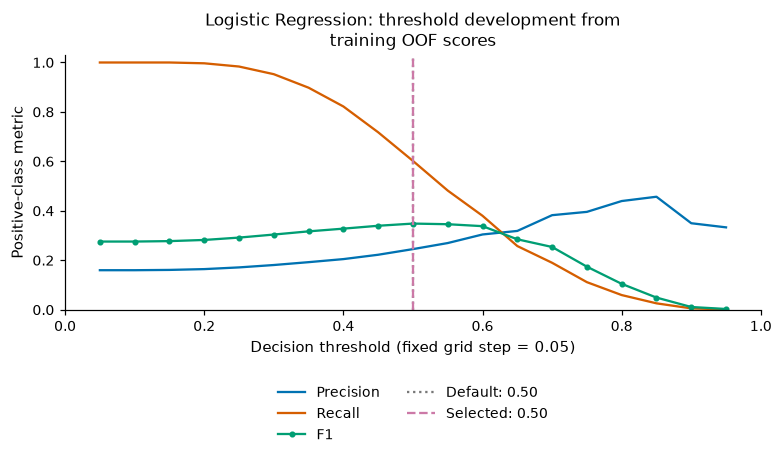

In [40]:
with warnings.catch_warnings():
    warnings.simplefilter("error", ConvergenceWarning)
    selected_oof_probabilities = cross_val_predict(
        selected_template, X_train, y_train, cv=cv_splits,
        method="predict_proba", n_jobs=1,
    )
assert selected_oof_probabilities.shape == (len(X_train), 2)
selected_oof_scores = selected_oof_probabilities[:, POSITIVE_CLASS]
threshold_rows = []
for threshold in THRESHOLD_GRID:
    prediction = (selected_oof_scores > threshold).astype(int)
    threshold_rows.append({
        "Threshold": float(threshold),
        "Precision": precision_score(y_train, prediction, zero_division=0),
        "Recall": recall_score(y_train, prediction, zero_division=0),
        "F1": f1_score(y_train, prediction, zero_division=0),
        "Balanced accuracy": balanced_accuracy_score(y_train, prediction),
        "Accuracy": accuracy_score(y_train, prediction),
        "Predicted positives": int(prediction.sum()),
    })
threshold_results = pd.DataFrame(threshold_rows).set_index("Threshold")
maximum_f1 = threshold_results["F1"].max()
selected_threshold = float(threshold_results.index[threshold_results["F1"].eq(maximum_f1)].max())
threshold_comparison = threshold_results.loc[
    sorted({DEFAULT_THRESHOLD, selected_threshold})
].copy()
print(f"Selected model: {selected_model_name}; threshold: {selected_threshold:.2f}.")
print("Decision rule: class 1 if its score is strictly greater than the threshold.")
print(f"Pooled out-of-fold AP: {average_precision_score(y_train, selected_oof_scores):.4f}; "
      f"ROC-AUC: {roc_auc_score(y_train, selected_oof_scores):.4f}.")
display(threshold_results.round(4))
display(threshold_comparison.round(4))
fig, ax = plt.subplots(figsize=(8.8, 5.1), layout="constrained")
for metric, color in [("Precision", "#0072B2"), ("Recall", "#D55E00"), ("F1", "#009E73")]:
    ax.plot(threshold_results.index, threshold_results[metric], color=color,
            marker="o" if metric == "F1" else None, markersize=3, label=metric)
ax.axvline(DEFAULT_THRESHOLD, color="#777777", linestyle=":", label="Default: 0.50")
ax.axvline(selected_threshold, color="#CC79A7", linestyle="--",
           label=f"Selected: {selected_threshold:.2f}")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.03)
ax.set_xlabel("Decision threshold (fixed grid step = 0.05)")
ax.set_ylabel("Positive-class metric")
ax.set_title(f"{selected_model_name}: threshold development from training OOF scores")
ax.grid(alpha=0.18)
ax.legend(loc="best", framealpha=1, fontsize=9)
export_figure(fig, "model_10_threshold_selection.png")
threshold_figure = figure_paths[-1]

### 7.5 Final Training Fit and Frozen Selection Record

In [41]:
with warnings.catch_warnings():
    warnings.simplefilter("error", ConvergenceWarning)
    selected_model = clone(selected_template).fit(X_train, y_train)
np.testing.assert_array_equal(selected_model.classes_, [0, 1])
training_assignment = split_assignments.loc[
    split_assignments["partition"].eq("train"), ["record_id", "cv_fold"]
].astype(int).sort_values("record_id").to_records(index=False).tolist()
training_assignment_sha256 = hashlib.sha256(
    json.dumps(training_assignment, separators=(",", ":")).encode("utf-8")
).hexdigest()
frozen_selection = {
    "selected_model": selected_model_name,
    "preprocessing": model_specs[selected_model_name]["preprocessing"],
    "classifier_parameters": selected_model.named_steps["classifier"].get_params(deep=False),
    "predictor_fields": predictor_fields,
    "positive_class": POSITIVE_CLASS,
    "threshold": selected_threshold,
    "decision_rule": "score > threshold",
    "model_selection_metric": "mean 10-fold average_precision",
    "threshold_selection_metric": THRESHOLD_METRIC,
    "threshold_grid": THRESHOLD_GRID.tolist(),
    "random_seed": RANDOM_STATE,
    "training_rows": len(X_train),
    "training_assignment_sha256": training_assignment_sha256,
    "source_sha256": source_sha256,
    "scikit_learn_version": sklearn.__version__,
}
SELECTION_PATH = Path("model_selection.json")
if SELECTION_PATH.exists():
    stored_selection = json.loads(SELECTION_PATH.read_text(encoding="utf-8"))
    assert stored_selection.get("initial_selection", stored_selection) == frozen_selection, (
        "Stored model/threshold selection differs; stop before held-out test evaluation."
    )
else:
    SELECTION_PATH.write_text(json.dumps(frozen_selection, indent=2, ensure_ascii=True) + "\n", encoding="utf-8")
print("Selected pipeline fitted on all 7,662 training records.")
print("Model and threshold selection saved and checked. Held-out test evaluation has not run.")
display(pd.Series({"Model": selected_model_name, "Threshold": selected_threshold,
                   "Training records": len(X_train), "Encoded fields": 19,
                   "Selection record": SELECTION_PATH.name}, name="Frozen setting").to_frame())

Selected pipeline fitted on all 7,662 training records.
Model and threshold selection saved and checked. Held-out test evaluation has not run.


,Frozen setting
Model,Logistic Regression
Threshold,0.5
Training records,7662
Encoded fields,19
Selection record,model_selection.json


### 7.6 Model Development Checks

In [42]:
assert len(configuration_results) == 13
assert len(selected_fold_scores) == 4 * N_FOLDS
assert set(X_train.index) == set(train_ids)
assert set(X_train.index).isdisjoint(test_ids)
pd.testing.assert_frame_equal(X_train, train_data[predictor_fields], check_exact=True)
pd.testing.assert_series_equal(y_train, train_data[TARGET], check_exact=True)
for name, search in model_searches.items():
    assert search.cv is cv_splits and search.n_splits_ == N_FOLDS
    assert len(search.cv_results_["params"]) == len(ParameterGrid(model_specs[name]["grid"]))
    assert not hasattr(search, "best_estimator_")
    for metric in scoring:
        fold_values = selected_fold_scores.loc[selected_fold_scores["Model"].eq(name), metric].to_numpy()
        assert len(fold_values) == N_FOLDS and np.isfinite(fold_values).all()
        np.testing.assert_allclose(model_comparison.loc[name, f"{metric} mean"], fold_values.mean())
        np.testing.assert_allclose(model_comparison.loc[name, f"{metric} SD"], fold_values.std(ddof=0))
    assert np.isfinite(search.cv_results_["mean_train_average_precision"]).all()
baseline_folds = selected_fold_scores.loc[selected_fold_scores["Model"].eq("Majority baseline")]
for fold, (_, validation_positions) in enumerate(cv_splits):
    observed_rate = y_train.iloc[validation_positions].mean()
    np.testing.assert_allclose(baseline_folds.iloc[fold]["average_precision"], observed_rate)
    np.testing.assert_allclose(baseline_folds.iloc[fold]["accuracy"], 1 - observed_rate)
np.testing.assert_allclose(baseline_folds["roc_auc"], 0.5)
np.testing.assert_allclose(baseline_folds[["precision", "recall", "f1"]], 0)
assert selected_model_name == model_comparison["average_precision mean"].idxmax()
assert np.isfinite(selected_oof_probabilities).all()
assert ((selected_oof_probabilities >= 0) & (selected_oof_probabilities <= 1)).all()
np.testing.assert_allclose(selected_oof_probabilities.sum(axis=1), 1)
assert len(threshold_results) == 19 and selected_threshold in THRESHOLD_GRID
assert threshold_results.loc[selected_threshold, "F1"] == maximum_f1
np.testing.assert_array_equal(np.array([0.5, 0.51, 0.4, 0.8]) > DEFAULT_THRESHOLD,
                              [False, True, False, True])

# One fold independently verifies OOF scores and fold-local learned preprocessing.
fit_positions, validation_positions = cv_splits[0]
probe_model = clone(selected_template).fit(X_train.iloc[fit_positions], y_train.iloc[fit_positions])
np.testing.assert_allclose(probe_model.predict_proba(X_train.iloc[validation_positions]),
                           selected_oof_probabilities[validation_positions], atol=1e-10)
probe_columns = probe_model.named_steps["preprocess"].named_steps["columns"]
assert probe_columns.named_transformers_["purpose"].categories_[0].tolist() == sorted(
    X_train.iloc[fit_positions]["purpose"].unique()
)
if model_specs[selected_model_name]["preprocessing"] == "scaled":
    np.testing.assert_allclose(probe_columns.named_transformers_["numeric"].mean_,
                               X_train.iloc[fit_positions][numeric_predictors].mean(), atol=1e-10)
assert selected_model.named_steps["preprocess"].transform(X_train.iloc[:1]).shape == (1, 19)
stored_selection = json.loads(SELECTION_PATH.read_text(encoding="utf-8"))
assert stored_selection.get("initial_selection", stored_selection) == frozen_selection
assert all(path.is_file() and path.stat().st_size > 10000
           for path in [model_comparison_figure, threshold_figure])
assert all(not hasattr(template["columns"], "transformers_")
           for template in preprocessing_pipelines.values())
assert hashlib.sha256(SOURCE_PATH.read_bytes()).hexdigest() == source_sha256
assert hashlib.sha256(DB_PATH.read_bytes()).hexdigest() == models_database_sha256
print("Model development checks passed: 13 configurations, identical folds, OOF coverage and threshold rule.")
print("Frozen selection matches the saved record. No held-out test predictions or scores were generated.")

Model development checks passed: 13 configurations, identical folds, OOF coverage and threshold rule.
Frozen selection matches the saved record. No held-out test predictions or scores were generated.


## 8. Initial Held-Out Evaluation

### 8.1 Frozen Selection and Test Scope

In [43]:
from sklearn.metrics import confusion_matrix, precision_recall_curve, roc_curve, auc

evaluation_database_sha256 = hashlib.sha256(DB_PATH.read_bytes()).hexdigest()
selection_record_sha256 = hashlib.sha256(SELECTION_PATH.read_bytes()).hexdigest()
evaluation_record = json.loads(SELECTION_PATH.read_text(encoding="utf-8"))
evaluation_selection = evaluation_record.get("initial_selection", evaluation_record)
assert evaluation_selection == frozen_selection
assert evaluation_selection["selected_model"] == selected_model_name == "Logistic Regression"
assert evaluation_selection["threshold"] == selected_threshold == 0.5
assert evaluation_selection["decision_rule"] == "score > threshold"
assert evaluation_selection["predictor_fields"] == predictor_fields
assert len(X_test) == 1916 and y_test.value_counts().to_dict() == {0: 1609, 1: 307}
assert set(X_test.index) == set(test_ids) and set(X_test.index).isdisjoint(X_train.index)
pd.testing.assert_frame_equal(X_test, test_data[predictor_fields], check_exact=True)
pd.testing.assert_series_equal(y_test, test_data[TARGET], check_exact=True)
assert selected_model.named_steps["classifier"].get_params(deep=False) == evaluation_selection["classifier_parameters"]
final_columns = selected_model.named_steps["preprocess"].named_steps["columns"]
np.testing.assert_allclose(final_columns.named_transformers_["numeric"].mean_,
                           X_train[numeric_predictors].mean(), atol=1e-10)
assert final_columns.named_transformers_["numeric"].n_samples_seen_ == len(X_train)
final_coefficients_before = selected_model.named_steps["classifier"].coef_.copy()
final_intercept_before = selected_model.named_steps["classifier"].intercept_.copy()

TEST_BOOTSTRAP_REPEATS = 2000
TEST_BOOTSTRAP_SEED = 42
ERROR_ORDER = ["TN", "FP", "FN", "TP"]
print("Frozen training fit verified. Evaluate the existing model and rule without test-based tuning.")
display(pd.Series({"Test records": len(X_test), "Class 0": int(y_test.eq(0).sum()),
                   "Class 1": int(y_test.eq(1).sum()), "Threshold": selected_threshold,
                   "Bootstrap repeats": TEST_BOOTSTRAP_REPEATS,
                   "Bootstrap seed": TEST_BOOTSTRAP_SEED}, name="Evaluation setting").to_frame())

Frozen training fit verified. Evaluate the existing model and rule without test-based tuning.


,Evaluation setting
Test records,1916.0
Class 0,1609.0
Class 1,307.0
Threshold,0.5
Bootstrap repeats,2000.0
Bootstrap seed,42.0


### 8.2 Fixed-Rule Metrics and Training-Fitted Baseline

In [44]:
test_probabilities = selected_model.predict_proba(X_test)
test_scores = test_probabilities[:, POSITIVE_CLASS]
test_predictions = (test_scores > selected_threshold).astype(int)
final_baseline = clone(model_templates["Majority baseline"]).fit(X_train, y_train)
baseline_test_scores = final_baseline.predict_proba(X_test)[:, POSITIVE_CLASS]
baseline_test_predictions = final_baseline.predict(X_test)

def evaluation_metrics(actual, scores, prediction):
    return {
        "AP": average_precision_score(actual, scores),
        "ROC-AUC": roc_auc_score(actual, scores),
        "Precision": precision_score(actual, prediction, zero_division=0),
        "Recall": recall_score(actual, prediction, zero_division=0),
        "F1": f1_score(actual, prediction, zero_division=0),
        "Balanced accuracy": balanced_accuracy_score(actual, prediction),
        "Accuracy": accuracy_score(actual, prediction),
    }

test_metric_rows = [
    {"Model": "Majority baseline", **evaluation_metrics(y_test, baseline_test_scores, baseline_test_predictions)},
    {"Model": selected_model_name, **evaluation_metrics(y_test, test_scores, test_predictions)},
]
test_metrics = pd.DataFrame(test_metric_rows).set_index("Model")
test_confusions = {
    "Majority baseline": confusion_matrix(y_test, baseline_test_predictions, labels=[0, 1]),
    selected_model_name: confusion_matrix(y_test, test_predictions, labels=[0, 1]),
}
tn, fp, fn, tp = test_confusions[selected_model_name].ravel()
error_rates = pd.Series({
    "True negatives": int(tn), "False positives": int(fp),
    "False negatives": int(fn), "True positives": int(tp),
    "False positive rate (FP / actual class 0)": fp / (tn + fp),
    "False negative rate (FN / actual class 1)": fn / (fn + tp),
    "False discovery share (FP / predicted class 1)": fp / (fp + tp) if fp + tp else np.nan,
    "Predicted positive share": (fp + tp) / len(y_test),
}, name="Held-out error result")
display(test_metrics.round(4))
display(error_rates)
print("Held-out scores computed with the frozen rule; no model or threshold was changed.")

,AP,ROC-AUC,Precision,Recall,F1,Balanced accuracy,Accuracy
Model,,,,,,,
Majority baseline,0.1602,0.5000,0.0000,0.00,0.0000,0.5000,0.8398
Logistic Regression,0.3028,0.6844,0.2394,0.57,0.3372,0.6122,0.6409


True negatives                                    1053.000000
False positives                                    556.000000
False negatives                                    132.000000
True positives                                     175.000000
False positive rate (FP / actual class 0)            0.345556
False negative rate (FN / actual class 1)            0.429967
False discovery share (FP / predicted class 1)       0.760602
Predicted positive share                             0.381524
Name: Held-out error result, dtype: float64

Held-out scores computed with the frozen rule; no model or threshold was changed.


### 8.3 Conditional Test Uncertainty

In [45]:
test_actual_array = y_test.to_numpy()
test_class_positions = [np.flatnonzero(test_actual_array == label) for label in [0, 1]]
test_bootstrap_rng = np.random.default_rng(TEST_BOOTSTRAP_SEED)
test_bootstrap_rows = []
for _ in range(TEST_BOOTSTRAP_REPEATS):
    resampled_positions = np.concatenate([
        test_bootstrap_rng.choice(positions, size=len(positions), replace=True)
        for positions in test_class_positions
    ])
    test_bootstrap_rows.append(evaluation_metrics(
        test_actual_array[resampled_positions],
        test_scores[resampled_positions], test_predictions[resampled_positions],
    ))
test_bootstrap_results = pd.DataFrame(test_bootstrap_rows)
test_intervals = pd.DataFrame({
    "Estimate": test_metrics.loc[selected_model_name],
    "95% lower": test_bootstrap_results.quantile(0.025),
    "95% upper": test_bootstrap_results.quantile(0.975),
})
display(test_intervals.round(4))
print("Pointwise percentile intervals: 2,000 stratified resamples, fixed model and observed class counts.")
print("Intervals exclude model refitting, model selection uncertainty, prevalence variability, borrower dependence and future drift.")

,Estimate,95% lower,95% upper
AP,0.3028,0.2664,0.3500
ROC-AUC,0.6844,0.6522,0.7155
Precision,0.2394,0.2183,0.2599
Recall,0.5700,0.5179,0.6221
F1,0.3372,0.3084,0.3656
Balanced accuracy,0.6122,0.5835,0.6409
Accuracy,0.6409,0.6190,0.6613


Pointwise percentile intervals: 2,000 stratified resamples, fixed model and observed class counts.
Intervals exclude model refitting, model selection uncertainty, prevalence variability, borrower dependence and future drift.


### 8.4 Confusion Matrices: Counts and Actual-Class Percentages

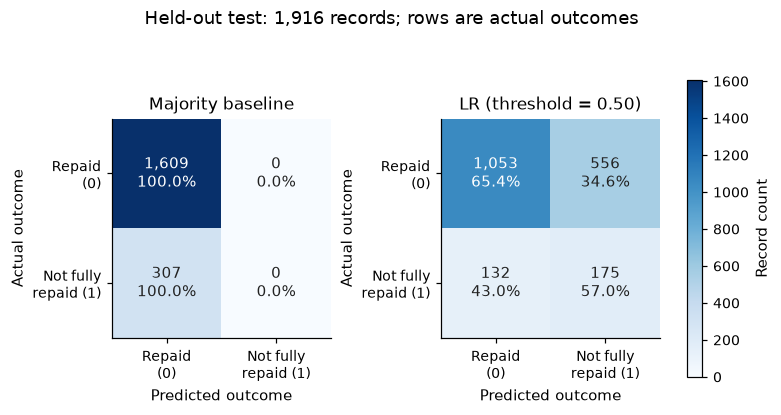

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(10.7, 4.5), layout="constrained")
test_label_names = ["Fully repaid (0)", "Not fully repaid (1)"]
matrix_vmax = max(int(matrix.max()) for matrix in test_confusions.values())
for ax, (name, matrix) in zip(axes, test_confusions.items()):
    image_handle = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=matrix_vmax)
    row_shares = matrix / matrix.sum(axis=1, keepdims=True)
    for row in range(2):
        for column in range(2):
            text_color = "white" if matrix[row, column] > matrix_vmax / 2 else "#222222"
            ax.text(column, row, f"{matrix[row, column]:,}\n{row_shares[row, column]:.1%}",
                    ha="center", va="center", fontsize=10, color=text_color)
    ax.set_xticks([0, 1], ["Repaid\n(0)", "Not fully\nrepaid (1)"])
    ax.set_yticks([0, 1], ["Repaid\n(0)", "Not fully\nrepaid (1)"])
    ax.set_xlabel("Predicted outcome")
    ax.set_ylabel("Actual outcome")
    ax.set_title(name if name == "Majority baseline" else "LR (threshold = 0.50)")
fig.colorbar(image_handle, ax=axes, shrink=0.78, label="Record count")
fig.suptitle("Held-out test: 1,916 records; rows are actual outcomes", fontsize=12)
export_figure(fig, "evaluation_11_confusion_matrices.png")
test_confusion_figure = figure_paths[-1]

### 8.5 Precision-Recall and ROC Curves

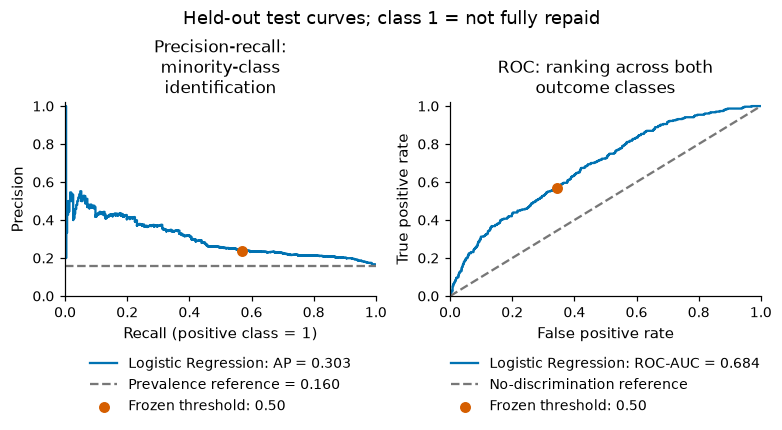

In [47]:
test_precision_curve, test_recall_curve, test_pr_thresholds = precision_recall_curve(
    y_test, test_scores, pos_label=POSITIVE_CLASS,
)
test_fpr_curve, test_tpr_curve, test_roc_thresholds = roc_curve(
    y_test, test_scores, pos_label=POSITIVE_CLASS, drop_intermediate=False,
)
test_positive_share = float(y_test.mean())
selected_test_metrics = test_metrics.loc[selected_model_name]
fig, axes = plt.subplots(1, 2, figsize=(10.7, 4.7), layout="constrained")
axes[0].step(test_recall_curve, test_precision_curve, where="post", color="#0072B2",
             label=f"Logistic Regression: AP = {selected_test_metrics['AP']:.3f}")
axes[0].axhline(test_positive_share, color="#777777", linestyle="--",
                label=f"Prevalence reference = {test_positive_share:.3f}")
axes[0].scatter(selected_test_metrics["Recall"], selected_test_metrics["Precision"],
                color="#D55E00", s=38, zorder=3, label="Frozen threshold: 0.50")
axes[0].set_xlabel("Recall (positive class = 1)")
axes[0].set_ylabel("Precision")
axes[0].set_title("Precision-recall: minority-class identification")
axes[1].plot(test_fpr_curve, test_tpr_curve, color="#0072B2",
             label=f"Logistic Regression: ROC-AUC = {selected_test_metrics['ROC-AUC']:.3f}")
axes[1].plot([0, 1], [0, 1], color="#777777", linestyle="--", label="No-discrimination reference")
axes[1].scatter(fp / (tn + fp), tp / (fn + tp), color="#D55E00", s=38, zorder=3,
                label="Frozen threshold: 0.50")
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate")
axes[1].set_title("ROC: ranking across both outcome classes")
for ax in axes:
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    ax.grid(alpha=0.18)
    ax.legend(loc="best", fontsize=9, framealpha=1)
fig.suptitle("Held-out test curves; class 1 = not fully repaid", fontsize=12)
export_figure(fig, "evaluation_12_pr_roc_curves.png")
test_curves_figure = figure_paths[-1]

### 8.6 Post-Evaluation Error Diagnostics

,Records,fico median,dti median,int.rate median,log.annual.inc median
Error group,,,,,
TN,1053,727.0,12.100,11.140,11.0021
FP,556,682.0,13.655,13.920,10.8590
FN,132,712.0,12.515,11.875,10.8590
TP,175,677.0,13.600,14.380,10.8198


,record_id,Error group,Actual,Predicted,Score,fico,dti,int.rate (%),log.annual.inc
0,8019,FP,0,1,0.9714,682,8.96,10.28,10.3090
1,1885,FN,1,0,0.1866,737,18.41,9.63,11.6082


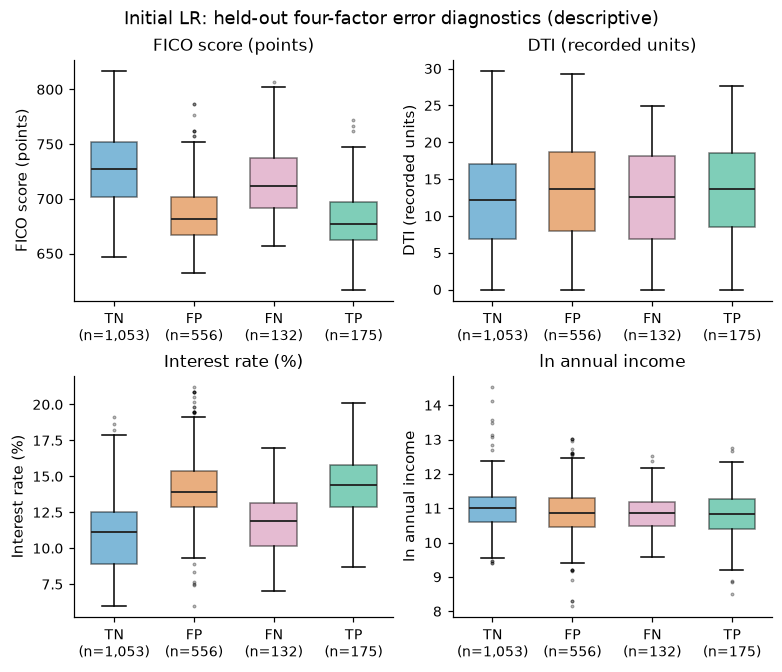

Examples use the highest-score false positive and lowest-score false negative; ties use record ID.
Post-evaluation group differences describe observed errors; they do not establish causes or new rules.


In [48]:
test_results = X_test.copy()
test_results["Actual"] = test_actual_array
test_results["Score"] = test_scores
test_results["Predicted"] = test_predictions
test_results["Error group"] = np.select([
    (test_actual_array == 0) & (test_predictions == 0),
    (test_actual_array == 0) & (test_predictions == 1),
    (test_actual_array == 1) & (test_predictions == 0),
    (test_actual_array == 1) & (test_predictions == 1),
], ERROR_ORDER, default="Unexpected")
error_plot_data = test_results[FOCUS_FACTORS].copy()
error_plot_data["int.rate"] *= 100
error_summary_rows = []
for group in ERROR_ORDER:
    group_values = error_plot_data.loc[test_results["Error group"].eq(group)]
    error_summary_rows.append({
        "Error group": group, "Records": len(group_values),
        **{f"{field} median": float(group_values[field].median()) for field in FOCUS_FACTORS},
    })
test_error_summary = pd.DataFrame(error_summary_rows).set_index("Error group")
example_rows = []
for group, ascending_score in [("FP", False), ("FN", True)]:
    group_records = test_results.loc[test_results["Error group"].eq(group)].reset_index()
    example_rows.append(group_records.sort_values(
        ["Score", "record_id"], ascending=[ascending_score, True]
    ).head(1))
test_error_examples = pd.concat(example_rows, ignore_index=True)
example_fields = ["record_id", "Error group", "Actual", "Predicted", "Score"] + FOCUS_FACTORS
display(test_error_summary.round(4))
example_display = test_error_examples[example_fields].rename(columns={"int.rate": "int.rate (%)"}).copy()
example_display["int.rate (%)"] *= 100
display(example_display.round(4))

fig, axes = plt.subplots(2, 2, figsize=(10.5, 7.2), layout="constrained")
diagnostic_colors = ["#0072B2", "#D55E00", "#CC79A7", "#009E73"]
group_labels = [f"{group}\n(n={int(test_error_summary.at[group, 'Records']):,})" for group in ERROR_ORDER]
for ax, field in zip(axes.flat, FOCUS_FACTORS):
    values = [error_plot_data.loc[test_results["Error group"].eq(group), field].to_numpy()
              for group in ERROR_ORDER]
    boxes = ax.boxplot(values, tick_labels=group_labels, patch_artist=True,
                       showfliers=True, widths=0.58,
                       flierprops={"marker": ".", "markersize": 3, "alpha": 0.4},
                       medianprops={"color": "#222222", "linewidth": 1.2})
    for patch, color in zip(boxes["boxes"], diagnostic_colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.5)
    ax.set_ylabel(FACTOR_LABELS[field])
    ax.set_title(FACTOR_LABELS[field])
    ax.grid(axis="y", alpha=0.18)
fig.suptitle("Initial LR: held-out four-factor error diagnostics (descriptive)", fontsize=12)
export_figure(fig, "evaluation_13_error_factor_distributions.png")
test_error_figure = figure_paths[-1]
print("Examples use the highest-score false positive and lowest-score false negative; ties use record ID.")
print("Post-evaluation group differences describe observed errors; they do not establish causes or new rules.")

### 8.7 Final Evaluation Checks

In [49]:
assert test_probabilities.shape == (1916, 2) and np.isfinite(test_probabilities).all()
np.testing.assert_allclose(test_probabilities.sum(axis=1), 1)
np.testing.assert_array_equal(test_predictions, selected_model.predict(X_test))
assert np.unique(baseline_test_predictions).tolist() == [0]
np.testing.assert_allclose(baseline_test_scores, y_train.mean())
np.testing.assert_allclose(test_metrics.loc["Majority baseline", "AP"], y_test.mean())
np.testing.assert_allclose(test_metrics.loc["Majority baseline", "ROC-AUC"], 0.5)
np.testing.assert_allclose(test_metrics.loc["Majority baseline", ["Precision", "Recall", "F1"]], 0)
np.testing.assert_allclose(test_metrics.loc["Majority baseline", "Accuracy"], 1609 / 1916)
assert test_confusions["Majority baseline"].tolist() == [[1609, 0], [307, 0]]
assert tn + fp == 1609 and fn + tp == 307 and tn + fp + fn + tp == 1916
manual_classification = {
    "Precision": tp / (tp + fp), "Recall": tp / (tp + fn),
    "F1": 2 * tp / (2 * tp + fp + fn),
    "Balanced accuracy": ((tp / (tp + fn)) + (tn / (tn + fp))) / 2,
    "Accuracy": (tp + tn) / 1916,
}
for metric, value in manual_classification.items():
    np.testing.assert_allclose(test_metrics.loc[selected_model_name, metric], value)
np.testing.assert_allclose(
    -np.sum(np.diff(test_recall_curve) * test_precision_curve[:-1]),
    test_metrics.loc[selected_model_name, "AP"],
)
np.testing.assert_allclose(auc(test_fpr_curve, test_tpr_curve),
                           test_metrics.loc[selected_model_name, "ROC-AUC"])
assert len(test_bootstrap_results) == TEST_BOOTSTRAP_REPEATS
assert np.isfinite(test_intervals.to_numpy()).all()
assert ((test_intervals >= 0) & (test_intervals <= 1)).all().all()
assert (test_intervals["95% lower"] <= test_intervals["95% upper"]).all()
assert test_error_summary["Records"].tolist() == [int(tn), int(fp), int(fn), int(tp)]
assert test_results["Error group"].isin(ERROR_ORDER).all()
assert test_results.index.is_unique and set(test_results.index) == set(test_ids)
assert test_error_examples["Error group"].tolist() == ["FP", "FN"]
np.testing.assert_allclose(
    test_error_examples.loc[test_error_examples["Error group"].eq("FP"), "Score"],
    test_results.loc[test_results["Error group"].eq("FP"), "Score"].max(),
)
np.testing.assert_allclose(
    test_error_examples.loc[test_error_examples["Error group"].eq("FN"), "Score"],
    test_results.loc[test_results["Error group"].eq("FN"), "Score"].min(),
)
np.testing.assert_array_equal(selected_model.named_steps["classifier"].coef_, final_coefficients_before)
np.testing.assert_array_equal(selected_model.named_steps["classifier"].intercept_, final_intercept_before)
assert json.loads(SELECTION_PATH.read_text(encoding="utf-8")) == evaluation_record
assert hashlib.sha256(SELECTION_PATH.read_bytes()).hexdigest() == selection_record_sha256
assert hashlib.sha256(SOURCE_PATH.read_bytes()).hexdigest() == source_sha256
assert hashlib.sha256(DB_PATH.read_bytes()).hexdigest() == evaluation_database_sha256
assert all(path.is_file() and path.stat().st_size > 10000 for path in [
    test_confusion_figure, test_curves_figure, test_error_figure,
])
print("Final evaluation checks passed: held-out coverage, metrics, curve areas, errors and frozen settings.")
print("Test diagnostics did not change the model, threshold, predictors or preprocessing.")

Final evaluation checks passed: held-out coverage, metrics, curve areas, errors and frozen settings.
Test diagnostics did not change the model, threshold, predictors or preprocessing.


## 9. Accuracy-Focused Revision

The original AP/F1 development and first evaluation above are retained as a comparison. This revision was requested after that evaluation was inspected. The 1,916-record test partition is therefore reused comparative evidence, not a fresh independent test. Selection below uses only the original 7,662 training records. Five outer folds evaluate configuration and threshold selection using three inner folds. A final ten-fold development search supplies the full-training fit. The outer results assess the three-inner-fold version, an approximate evaluation of the final tuning procedure with a different resampling regime.

The lecturer-provided CSV remains the only source of observations. Public reference: [pedro-nunesm, Random Forest Model vs Decision Tree Classifier](https://github.com/pedro-nunesm/Random-Forests-Model-x-Decision-Tree-Classifier-on-LendingClub-Dataset/tree/7d86caf3282beb3fd5a339f3977822cbdb9b7e26). Its CSV was verified byte-for-byte and value-for-value on 7 October 2026. Only methodological ideas are reused; evaluation splits and results are computed here.

In [50]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import FunctionTransformer
from sklearn.inspection import permutation_importance
from joblib import Parallel, delayed
from threadpoolctl import threadpool_limits

PUBLIC_REFERENCE = {
    "repository": "pedro-nunesm/Random-Forests-Model-x-Decision-Tree-Classifier-on-LendingClub-Dataset",
    "commit": "7d86caf3282beb3fd5a339f3977822cbdb9b7e26",
    "csv_sha256": "91969386d42aa27a910a464b7987a9b225451282fa2934baf2c1afb9ef6480c7",
    "verification_date": "2026-10-07",
    "records": 9578, "fields": 14,
    "byte_identical": True, "parsed_values_identical": True,
}
assert PUBLIC_REFERENCE["csv_sha256"] == source_sha256
display(pd.Series(PUBLIC_REFERENCE, name="Verified public reference").to_frame())

tail_fields = ["revol.bal", "inq.last.6mths"]
log_numeric = ColumnTransformer([
    ("ordinary", StandardScaler(), [f for f in numeric_predictors if f not in tail_fields]),
    ("log_tail", Pipeline([
        ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("scale", StandardScaler()),
    ]), tail_fields),
    ("binary", "passthrough", binary_predictors),
    ("purpose", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_predictors),
])
revision_preprocessors = {
    **preprocessing_pipelines, "log_scaled": Pipeline([("columns", log_numeric)]),
}
ACCURACY_THRESHOLDS = np.round(np.arange(0.05, 0.951, 0.01), 2)
OUTER_FOLDS, INNER_FOLDS = 5, 3
OUTER_SEED = 2026
SEARCH_JOBS = 6
revision_specs = {
    "Majority baseline": (["unscaled"], DummyClassifier(strategy="prior"), {}),
    "Logistic Regression": (
        ["scaled", "log_scaled"],
        LogisticRegression(solver="lbfgs", l1_ratio=0.0, max_iter=4000),
        {"classifier__C": [0.1, 1.0, 10.0], "classifier__class_weight": [None, "balanced"]},
    ),
    "Decision Tree": (
        ["unscaled"], DecisionTreeClassifier(random_state=RANDOM_STATE),
        {"classifier__max_depth": [3, 6, None], "classifier__min_samples_leaf": [20, 50],
         "classifier__class_weight": [None, "balanced"]},
    ),
    "Random Forest": (
        ["unscaled"], RandomForestClassifier(n_estimators=300, max_features="sqrt",
                                            random_state=RANDOM_STATE, n_jobs=1),
        {"classifier__max_depth": [8, None], "classifier__min_samples_leaf": [1, 5, 20],
         "classifier__class_weight": [None, "balanced"]},
    ),
    "Gaussian Naive Bayes": (
        ["scaled", "log_scaled"], GaussianNB(),
        {"classifier__var_smoothing": [1e-9, 1e-3]},
    ),
    "kNN": (
        ["scaled"], KNeighborsClassifier(n_jobs=1),
        {"classifier__n_neighbors": [15, 51, 101],
         "classifier__weights": ["uniform", "distance"]},
    ),
    "Histogram Gradient Boosting": (
        ["unscaled"],
        HistGradientBoostingClassifier(max_iter=150, l2_regularization=1.0,
                                       early_stopping=False, random_state=RANDOM_STATE),
        {"classifier__max_leaf_nodes": [7, 15, 31],
         "classifier__learning_rate": [0.05, 0.1],
         "classifier__class_weight": [None, "balanced"]},
    ),
}
accuracy_candidates = []
for family, (preprocessors, classifier, grid) in revision_specs.items():
    for preprocessing in preprocessors:
        template = Pipeline([
            ("preprocess", clone(revision_preprocessors[preprocessing])),
            ("classifier", clone(classifier)),
        ])
        for parameters in ParameterGrid(grid):
            accuracy_candidates.append({
                "Family": family, "Preprocessing": preprocessing, "Parameters": parameters,
                "Template": clone(template).set_params(**parameters),
            })
# The reference notebook uses the default 100-tree, unrestricted random forest.
# Its method is evaluated with our fixed seed and fold-local encoding.
accuracy_candidates.append({
    "Family": "Random Forest", "Preprocessing": "unscaled",
    "Parameters": {"classifier__n_estimators": 100, "classifier__min_samples_leaf": 1,
                   "classifier__max_depth": None, "classifier__class_weight": None},
    "Template": Pipeline([
        ("preprocess", clone(preprocessing_pipelines["unscaled"])),
        ("classifier", RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=1)),
    ]),
})
revision_plan = pd.DataFrame([
    {"Candidate": i, **{k: candidate[k] for k in ["Family", "Preprocessing", "Parameters"]}}
    for i, candidate in enumerate(accuracy_candidates)
])
assert len(accuracy_candidates) == 60
display(revision_plan.groupby("Family", sort=False).size().rename("Configurations").to_frame())
print("Selection: highest pooled inner-OOF accuracy; ties use F1, AP, candidate order,")
print("then proximity to 0.50 and the lower threshold. All rules are fixed before new evaluation.")
print("A second F1 threshold on the same selected classifier supports risk-screening comparison.")


,Verified public reference
repository,pedro-nunesm/Random-Forests-Model-x-Decision-T...
commit,7d86caf3282beb3fd5a339f3977822cbdb9b7e26
csv_sha256,91969386d42aa27a910a464b7987a9b225451282fa2934...
verification_date,2026-10-07
records,9578
fields,14
byte_identical,True
parsed_values_identical,True


,Configurations
Family,
Majority baseline,1
Logistic Regression,12
Decision Tree,12
Random Forest,13
Gaussian Naive Bayes,4
kNN,6
Histogram Gradient Boosting,12


Selection: highest pooled inner-OOF accuracy; ties use F1, AP, candidate order,
then proximity to 0.50 and the lower threshold. All rules are fixed before new evaluation.
A second F1 threshold on the same selected classifier supports risk-screening comparison.


### 9.2 Candidate Predictions and Prespecified Selection

In [51]:
def candidate_oof(candidate, features, target, splits):
    scores = np.full(len(target), np.nan)
    coverage = np.zeros(len(target), dtype=int)
    with threadpool_limits(limits=1), warnings.catch_warnings():
        warnings.simplefilter("error", ConvergenceWarning)
        for fit_positions, validation_positions in splits:
            assert set(features.index[fit_positions]).isdisjoint(features.index[validation_positions])
            model = clone(candidate["Template"]).fit(
                features.iloc[fit_positions], target.iloc[fit_positions]
            )
            scores[validation_positions] = model.predict_proba(
                features.iloc[validation_positions]
            )[:, POSITIVE_CLASS]
            coverage[validation_positions] += 1
    assert (coverage == 1).all() and np.isfinite(scores).all()
    assert ((scores >= 0) & (scores <= 1)).all()
    return scores

def threshold_table(actual, scores):
    truth = np.asarray(actual) == POSITIVE_CLASS
    predictions = scores[:, None] > ACCURACY_THRESHOLDS[None, :]
    positives, negatives = int(truth.sum()), int((~truth).sum())
    true_positive = predictions[truth].sum(axis=0)
    false_positive = predictions[~truth].sum(axis=0)
    false_negative = positives - true_positive
    true_negative = negatives - false_positive
    predicted_positive = true_positive + false_positive
    return pd.DataFrame({
        "Threshold": ACCURACY_THRESHOLDS,
        "Accuracy": (true_positive + true_negative) / len(truth),
        "Precision": np.divide(true_positive, predicted_positive,
                               out=np.zeros(len(ACCURACY_THRESHOLDS)), where=predicted_positive > 0),
        "Recall": true_positive / positives,
        "F1": 2 * true_positive / (2 * true_positive + false_positive + false_negative),
        "Balanced accuracy": (true_positive / positives + true_negative / negatives) / 2,
        "Predicted positives": predicted_positive,
        "Distance to default": np.abs(ACCURACY_THRESHOLDS - 0.5),
    })

def ranked_accuracy(rows):
    return rows.sort_values(
        ["Accuracy", "F1", "AP", "Candidate", "Distance to default", "Threshold"],
        ascending=[False, False, False, True, True, True], kind="stable",
    )

def training_accuracy_search(features, target, splits):
    oof = Parallel(n_jobs=SEARCH_JOBS, max_nbytes=None)(
        delayed(candidate_oof)(candidate, features, target, splits)
        for candidate in accuracy_candidates
    )
    tables = []
    for i, (candidate, scores) in enumerate(zip(accuracy_candidates, oof)):
        rows = threshold_table(target, scores)
        rows["Candidate"] = i
        rows["Family"] = candidate["Family"]
        rows["Preprocessing"] = candidate["Preprocessing"]
        rows["AP"] = average_precision_score(target, scores)
        rows["ROC-AUC"] = roc_auc_score(target, scores)
        tables.append(rows)
    table = pd.concat(tables, ignore_index=True)
    winner = ranked_accuracy(table).iloc[0].copy()
    index = int(winner["Candidate"])
    screening = table.loc[table["Candidate"].eq(index)].sort_values(
        ["F1", "Threshold"], ascending=[False, False], kind="stable"
    ).iloc[0].copy()
    return winner, screening, table, oof

# A tied synthetic score independently checks the strict threshold and metric formulas.
check_actual = np.array([0, 0, 1, 1])
check_scores = np.array([0.1, 0.5, 0.5, 0.9])
check_row = threshold_table(check_actual, check_scores).loc[
    lambda frame: frame["Threshold"].eq(0.5)
].iloc[0]
assert check_row["Accuracy"] == 0.75 and check_row["Recall"] == 0.5
assert check_row["Precision"] == 1.0
np.testing.assert_allclose(check_row["F1"], 2 / 3)


### 9.3 Nested Training-Only Evaluation and Predictor Reliance

In [52]:
outer_splits = list(StratifiedKFold(
    n_splits=OUTER_FOLDS, shuffle=True, random_state=OUTER_SEED
).split(X_train, y_train))
nested_predictions = {name: np.full(len(y_train), -1, dtype=int)
                      for name in ["Accuracy rule", "F1 screening rule", "Majority baseline", "Initial LR rule"]}
nested_scores = {name: np.full(len(y_train), np.nan) for name in nested_predictions}
nested_coverage = np.zeros(len(y_train), dtype=int)
nested_metric_rows, nested_selection_rows, permutation_rows = [], [], []
for fold, (fit_positions, validation_positions) in enumerate(outer_splits, start=1):
    outer_fit_x, outer_fit_y = X_train.iloc[fit_positions], y_train.iloc[fit_positions]
    outer_valid_x, outer_valid_y = X_train.iloc[validation_positions], y_train.iloc[validation_positions]
    assert set(outer_fit_x.index).isdisjoint(outer_valid_x.index)
    assert (set(outer_fit_x.index) | set(outer_valid_x.index)).isdisjoint(test_ids)
    inner_splits = list(StratifiedKFold(
        n_splits=INNER_FOLDS, shuffle=True, random_state=RANDOM_STATE + fold
    ).split(outer_fit_x, outer_fit_y))
    winner, screening, _, _ = training_accuracy_search(outer_fit_x, outer_fit_y, inner_splits)
    candidate_index = int(winner["Candidate"])
    with threadpool_limits(limits=1):
        model = clone(accuracy_candidates[candidate_index]["Template"]).fit(outer_fit_x, outer_fit_y)
        scores = model.predict_proba(outer_valid_x)[:, POSITIVE_CLASS]
        initial_model = clone(selected_template).fit(outer_fit_x, outer_fit_y)
        initial_scores = initial_model.predict_proba(outer_valid_x)[:, POSITIVE_CLASS]
    fold_rules = {
        "Accuracy rule": (scores, (scores > float(winner["Threshold"])).astype(int)),
        "F1 screening rule": (scores, (scores > float(screening["Threshold"])).astype(int)),
        "Majority baseline": (np.full(len(outer_valid_y), outer_fit_y.mean()), np.zeros(len(outer_valid_y), dtype=int)),
        "Initial LR rule": (initial_scores, (initial_scores > selected_threshold).astype(int)),
    }
    for name, (rule_scores, prediction) in fold_rules.items():
        nested_predictions[name][validation_positions] = prediction
        nested_scores[name][validation_positions] = rule_scores
        nested_metric_rows.append({
            "Fold": fold, "Rule": name, **evaluation_metrics(outer_valid_y, rule_scores, prediction),
        })
    nested_coverage[validation_positions] += 1
    nested_selection_rows.append({
        "Fold": fold, "Fit records": len(outer_fit_y), "Validation records": len(outer_valid_y),
        "Candidate": candidate_index, "Family": winner["Family"],
        "Preprocessing": winner["Preprocessing"],
        "Accuracy threshold": float(winner["Threshold"]),
        "F1 threshold": float(screening["Threshold"]),
        "Inner OOF accuracy": float(winner["Accuracy"]),
        "Parameters": accuracy_candidates[candidate_index]["Parameters"],
    })
    with threadpool_limits(limits=1):
        importance = permutation_importance(
            model, outer_valid_x, outer_valid_y, scoring="average_precision",
            n_repeats=5, random_state=RANDOM_STATE + fold, n_jobs=1,
        )
        for j, field in enumerate(predictor_fields):
            for repeat, decrease in enumerate(importance.importances[j], start=1):
                permutation_rows.append({"Fold": fold, "Feature": field,
                                         "Repeat": repeat, "AP decrease": float(decrease)})
        # The same row permutation jointly preserves the internal FICO/rate association.
        rng = np.random.default_rng(RANDOM_STATE + fold)
        original_ap = average_precision_score(outer_valid_y, scores)
        for repeat in range(1, 6):
            shuffled = outer_valid_x.copy()
            positions = rng.permutation(len(shuffled))
            shuffled[["fico", "int.rate"]] = outer_valid_x[["fico", "int.rate"]].iloc[positions].to_numpy()
            changed_scores = model.predict_proba(shuffled)[:, POSITIVE_CLASS]
            permutation_rows.append({
                "Fold": fold, "Feature": "fico + int.rate", "Repeat": repeat,
                "AP decrease": float(original_ap - average_precision_score(outer_valid_y, changed_scores)),
            })
    print(f"Outer fold {fold}/{OUTER_FOLDS}: {winner['Family']}, threshold {winner['Threshold']:.2f}; "
          f"accuracy {nested_metric_rows[-4]['Accuracy']:.4f}", flush=True)
nested_fold_results = pd.DataFrame(nested_metric_rows)
nested_selection = pd.DataFrame(nested_selection_rows)
nested_summary = nested_fold_results.groupby("Rule", sort=False)[list(evaluation_metrics(
    y_train, nested_scores["Accuracy rule"], nested_predictions["Accuracy rule"]
))].agg(["mean", "std"])
nested_pooled = pd.DataFrame([
    {"Rule": name, **evaluation_metrics(y_train, nested_scores[name], nested_predictions[name])}
    for name in nested_predictions
]).set_index("Rule")
permutation_results = pd.DataFrame(permutation_rows)
permutation_summary = permutation_results.groupby("Feature")["AP decrease"].agg(["mean", "std"])
assert (nested_coverage == 1).all()
assert all(np.isfinite(scores).all() for scores in nested_scores.values())
display(nested_selection)
display(nested_summary.round(4))
display(nested_pooled.round(4))
display(permutation_summary.sort_values("mean", ascending=False).round(4))
print("Outer results evaluate three-inner-fold selection; final development uses ten folds. Folds can select different configurations.")
print("Permutation dispersion is descriptive, not a confidence interval or causal effect.")


Outer fold 1/5: Logistic Regression, threshold 0.85; accuracy 0.8356


Outer fold 2/5: Random Forest, threshold 0.52; accuracy 0.8382


Outer fold 3/5: Histogram Gradient Boosting, threshold 0.88; accuracy 0.8394


Outer fold 4/5: Random Forest, threshold 0.72; accuracy 0.8407


Outer fold 5/5: Logistic Regression, threshold 0.88; accuracy 0.8388


,Fold,Fit records,Validation records,Candidate,Family,Preprocessing,Accuracy threshold,F1 threshold,Inner OOF accuracy,Parameters
0,1,6129,1533,2,Logistic Regression,scaled,0.85,0.51,0.841573,"{'classifier__C': 0.1, 'classifier__class_weig..."
1,2,6129,1533,28,Random Forest,unscaled,0.52,0.21,0.841247,"{'classifier__class_weight': None, 'classifier..."
2,3,6130,1532,58,Histogram Gradient Boosting,unscaled,0.88,0.27,0.841599,"{'classifier__class_weight': 'balanced', 'clas..."
3,4,6130,1532,34,Random Forest,unscaled,0.72,0.25,0.841109,"{'classifier__class_weight': 'balanced', 'clas..."
4,5,6130,1532,4,Logistic Regression,scaled,0.88,0.46,0.840783,"{'classifier__C': 1.0, 'classifier__class_weig..."


AP         ROC-AUC         Precision          Recall  \
                     mean     std    mean     std      mean     std    mean   
Rule                                                                          
Accuracy rule      0.2665  0.0090  0.6576  0.0164    0.3614  0.3819  0.0057   
F1 screening rule  0.2665  0.0090  0.6576  0.0164    0.2298  0.0252  0.6241   
Majority baseline  0.1600  0.0003  0.5000  0.0000    0.0000  0.0000  0.0000   
Initial LR rule    0.2892  0.0367  0.6774  0.0320    0.2445  0.0166  0.5971   

                               F1         Balanced accuracy         Accuracy  \
                      std    mean     std              mean     std     mean   
Rule                                                                           
Accuracy rule      0.0047  0.0111  0.0090            0.5015  0.0018   0.8386   
F1 screening rule  0.1116  0.3317  0.0147            0.6073  0.0164   0.5958   
Majority baseline  0.0000  0.0000  0.0000            0.5000  0.0000   0.8400   
Initial LR rule    0.0463  0.3468  0.0232            0.6227  0.0243   0.6402   

                           
                      std  
Rule                       
Accuracy rule      0.0019  
F1 screening rule  0.0818  
Majority baseline  0.0003  
Initial LR rule    0.0180

,AP,ROC-AUC,Precision,Recall,F1,Balanced accuracy,Accuracy
Rule,,,,,,,
Accuracy rule,0.2376,0.6227,0.2800,0.0057,0.0112,0.5015,0.8386
F1 screening rule,0.2376,0.6227,0.2249,0.6240,0.3307,0.6072,0.5958
Majority baseline,0.1599,0.4996,0.0000,0.0000,0.0000,0.5000,0.8400
Initial LR rule,0.2819,0.6767,0.2444,0.5971,0.3468,0.6227,0.6402


,mean,std
Feature,,
fico + int.rate,0.0330,0.0117
inq.last.6mths,0.0279,0.0103
purpose,0.0168,0.0110
fico,0.0168,0.0145
installment,0.0152,0.0156
int.rate,0.0131,0.0107
credit.policy,0.0117,0.0110
revol.util,0.0108,0.0071
log.annual.inc,0.0090,0.0096


Outer results evaluate three-inner-fold selection; final development uses ten folds. Folds can select different configurations.
Permutation dispersion is descriptive, not a confidence interval or causal effect.


### 9.4 Final Ten-Fold Development Search

In [53]:
accuracy_winner, screening_winner, accuracy_threshold_results, accuracy_oof = training_accuracy_search(
    X_train, y_train, cv_splits
)
accuracy_candidate_index = int(accuracy_winner["Candidate"])
accuracy_candidate = accuracy_candidates[accuracy_candidate_index]
accuracy_family_results = ranked_accuracy(accuracy_threshold_results).groupby(
    "Family", sort=False
).head(1).copy()
accuracy_rule_threshold = float(accuracy_winner["Threshold"])
screening_rule_threshold = float(screening_winner["Threshold"])
revised_template = clone(accuracy_candidate["Template"])
revised_oof_scores = accuracy_oof[accuracy_candidate_index]
selected_revision_thresholds = accuracy_threshold_results.loc[
    accuracy_threshold_results["Candidate"].eq(accuracy_candidate_index)
].copy()
accuracy_native_results = pd.DataFrame([
    {"Family": candidate["Family"], "Candidate": i,
     **evaluation_metrics(y_train, scores, (scores > 0.5).astype(int))}
    for i, (candidate, scores) in enumerate(zip(accuracy_candidates, accuracy_oof))
])
display(accuracy_family_results[
    ["Family", "Candidate", "Preprocessing", "Threshold", "Accuracy", "AP", "ROC-AUC", "Precision", "Recall", "F1"]
].round(4))
display(pd.Series({
    "Family": accuracy_winner["Family"], "Candidate": accuracy_candidate_index,
    "Preprocessing": accuracy_candidate["Preprocessing"],
    "Parameters": accuracy_candidate["Parameters"],
    "Accuracy threshold": accuracy_rule_threshold, "F1 screening threshold": screening_rule_threshold,
}, name="Final development selection").to_frame())
print("Final development scores include selection optimism. Prefer nested outer results for procedure assessment.")


,Family,Candidate,Preprocessing,Threshold,Accuracy,AP,ROC-AUC,Precision,Recall,F1
4509,Histogram Gradient Boosting,49,unscaled,0.55,0.8417,0.2648,0.6522,0.6757,0.0204,0.0396
3253,Random Forest,35,unscaled,0.73,0.8412,0.2706,0.6613,0.6098,0.0204,0.0395
807,Logistic Regression,8,log_scaled,0.84,0.8408,0.2817,0.6747,0.5652,0.0212,0.0409
3953,kNN,43,scaled,0.45,0.8405,0.2510,0.6402,0.6250,0.0082,0.0161
1612,Decision Tree,17,unscaled,0.70,0.8401,0.2255,0.5946,0.5135,0.0155,0.0301
45,Majority baseline,0,unscaled,0.50,0.8400,0.1596,0.4988,0.0000,0.0000,0.0000
3730,Gaussian Naive Bayes,40,log_scaled,0.95,0.8292,0.2612,0.6589,0.3502,0.0791,0.1291


,Final development selection
Family,Histogram Gradient Boosting
Candidate,49
Preprocessing,unscaled
Parameters,"{'classifier__class_weight': None, 'classifier..."
Accuracy threshold,0.55
F1 screening threshold,0.18


Final development scores include selection optimism. Prefer nested outer results for procedure assessment.


### 9.5 Development Comparisons, Reliance and Threshold Tradeoffs

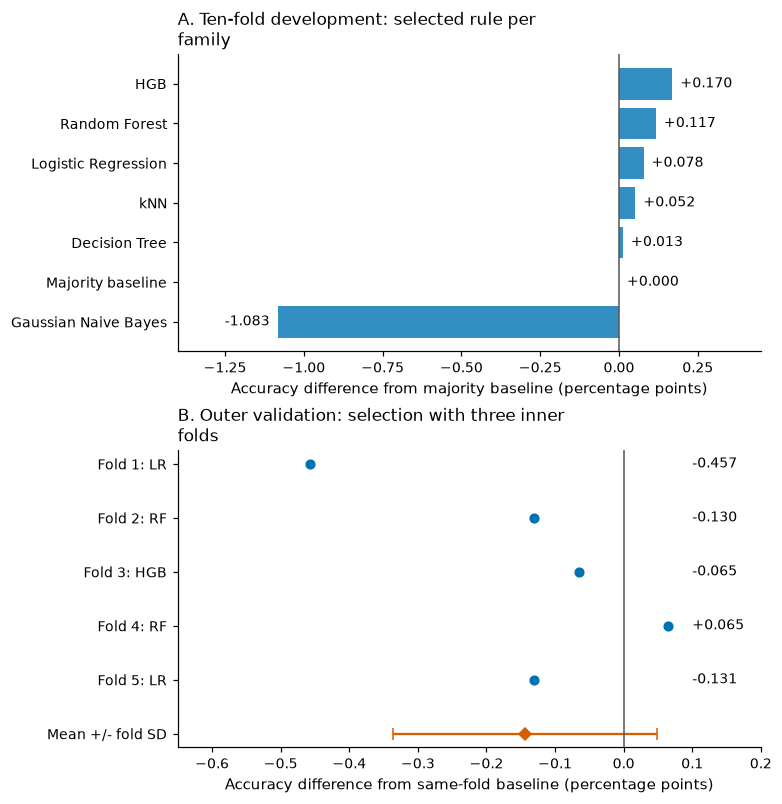

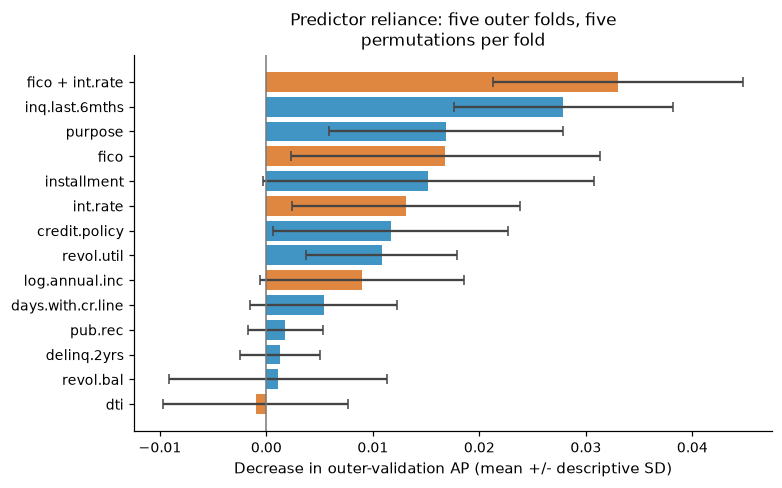

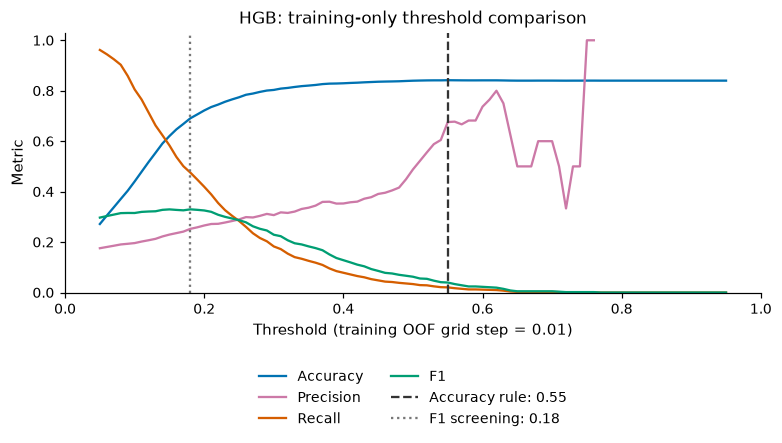

In [54]:
# Display small gains directly, with zero representing the matched baseline.
fig, axes = plt.subplots(2, 1, figsize=(7.0, 7.2), layout="constrained")
family_display = accuracy_family_results.sort_values("Accuracy", ascending=True).copy()
development_baseline = float(family_display.loc[
    family_display["Family"].eq("Majority baseline"), "Accuracy"
].iloc[0])
family_display["Difference (pp)"] = 100 * (family_display["Accuracy"] - development_baseline)
family_names = family_display["Family"].replace({"Histogram Gradient Boosting": "HGB"})
axes[0].barh(family_names, family_display["Difference (pp)"], color="#0072B2", alpha=0.8)
for pos, difference in enumerate(family_display["Difference (pp)"]):
    axes[0].text(difference + (0.025 if difference >= 0 else -0.025), pos,
                 f"{difference:+.3f}", va="center",
                 ha="left" if difference >= 0 else "right", fontsize=9)
axes[0].set_xlim(-1.4, 0.45)
axes[0].set_xlabel("Accuracy difference from majority baseline (percentage points)")
axes[0].set_title("A. Ten-fold development: selected rule per family", loc="left")

paired_accuracy = nested_fold_results.pivot(index="Fold", columns="Rule", values="Accuracy")
outer_differences = 100 * (paired_accuracy["Accuracy rule"] - paired_accuracy["Majority baseline"])
selected_families = nested_selection.set_index("Fold")["Family"].replace({
    "Logistic Regression": "LR", "Random Forest": "RF", "Histogram Gradient Boosting": "HGB"
})
fold_labels = [f"Fold {fold}: {selected_families.at[fold]}" for fold in outer_differences.index]
axes[1].scatter(outer_differences, range(OUTER_FOLDS), color="#0072B2", s=32)
axes[1].errorbar(outer_differences.mean(), OUTER_FOLDS,
                 xerr=outer_differences.std(ddof=1), fmt="D", color="#D55E00", capsize=4)
axes[1].set_yticks(range(OUTER_FOLDS + 1), fold_labels + ["Mean +/- fold SD"])
for pos, difference in enumerate(outer_differences):
    axes[1].text(0.1, pos, f"{difference:+.3f}", va="center", fontsize=9)
axes[1].invert_yaxis()
axes[1].set_xlim(-0.65, 0.2)
axes[1].set_xlabel("Accuracy difference from same-fold baseline (percentage points)")
axes[1].set_title("B. Outer validation: selection with three inner folds", loc="left")
for ax in axes:
    ax.axvline(0, color="#555555", linewidth=1)
    ax.grid(axis="x", alpha=0.15)
    ax.set_axisbelow(True)
export_figure(fig, "revision_14_accuracy_comparison.png")

importance_display = permutation_summary.sort_values("mean")
fig, ax = plt.subplots(figsize=(10.2, 6.3), layout="constrained")
colors = ["#D55E00" if f in FOCUS_FACTORS or f == "fico + int.rate" else "#0072B2"
          for f in importance_display.index]
ax.barh(importance_display.index, importance_display["mean"], color=colors, alpha=0.75)
ax.errorbar(importance_display["mean"], range(len(importance_display)), xerr=importance_display["std"],
            fmt="none", ecolor="#444444", capsize=3)
ax.axvline(0, color="#777777", linewidth=1)
ax.set_xlabel("Decrease in outer-validation AP (mean +/- descriptive SD)")
ax.set_title("Predictor reliance: five outer folds, five permutations per fold")
ax.grid(axis="x", alpha=0.15)
ax.set_axisbelow(True)
export_figure(fig, "revision_15_predictor_reliance.png")

fig, ax = plt.subplots(figsize=(9.3, 5.2), layout="constrained")
for metric, color in [("Accuracy", "#0072B2"), ("Precision", "#CC79A7"),
                      ("Recall", "#D55E00"), ("F1", "#009E73")]:
    displayed_values = selected_revision_thresholds[metric].copy()
    if metric == "Precision":
        displayed_values = displayed_values.where(selected_revision_thresholds["Predicted positives"].gt(0))
    ax.plot(selected_revision_thresholds["Threshold"], displayed_values,
            color=color, label=metric)
ax.axvline(accuracy_rule_threshold, color="#333333", linestyle="--",
           label=f"Accuracy rule: {accuracy_rule_threshold:.2f}")
ax.axvline(screening_rule_threshold, color="#777777", linestyle=":",
           label=f"F1 screening: {screening_rule_threshold:.2f}")
ax.set(xlim=(0, 1), ylim=(0, 1.03), xlabel="Threshold (training OOF grid step = 0.01)",
       ylabel="Metric", title="HGB: training-only threshold comparison")
ax.legend(framealpha=1, fontsize=9)
ax.grid(alpha=0.15)
export_figure(fig, "revision_16_threshold_tradeoffs.png")


### 9.6 Full-Training Fit and Revised Selection Record

In [55]:
with threadpool_limits(limits=1):
    revised_model = clone(revised_template).fit(X_train, y_train)
revised_frozen_selection = {
    "selected_model": str(accuracy_winner["Family"]),
    "preprocessing": accuracy_candidate["Preprocessing"],
    "classifier_parameters": revised_model.named_steps["classifier"].get_params(deep=False),
    "predictor_fields": predictor_fields, "positive_class": POSITIVE_CLASS,
    "threshold": accuracy_rule_threshold, "screening_threshold": screening_rule_threshold,
    "decision_rule": "score > threshold",
    "model_selection_metric": "pooled training-only OOF accuracy; joint configuration/threshold selection",
    "tie_breaking": "F1, AP, candidate order, distance to 0.50, lower threshold",
    "threshold_grid": ACCURACY_THRESHOLDS.tolist(), "random_seed": RANDOM_STATE,
    "training_rows": len(X_train), "training_assignment_sha256": training_assignment_sha256,
    "source_sha256": source_sha256, "scikit_learn_version": sklearn.__version__,
    "nested_validation": {"outer_folds": OUTER_FOLDS, "outer_seed": OUTER_SEED,
                          "inner_folds": INNER_FOLDS, "inner_seed": "42 + outer fold number",
                          "candidate_configurations": len(accuracy_candidates)},
    "public_reference": PUBLIC_REFERENCE,
    "evaluation_status": "revision after first test inspection; original test reused for comparison",
    "initial_selection": frozen_selection,
}
if "initial_selection" in evaluation_record:
    assert evaluation_record == revised_frozen_selection, "Revised selection changed on rerun."
else:
    SELECTION_PATH.write_text(json.dumps(revised_frozen_selection, indent=2, ensure_ascii=True) + "\n",
                              encoding="utf-8")
revised_selection_sha256 = hashlib.sha256(SELECTION_PATH.read_bytes()).hexdigest()
display(pd.Series({"Selected family": accuracy_winner["Family"],
                   "Accuracy threshold": accuracy_rule_threshold,
                   "F1 screening threshold": screening_rule_threshold,
                   "Training records": len(X_train)}, name="Revised frozen setting").to_frame())
print("Selection and both rules are fixed before recomputing the reused test comparison.")


,Revised frozen setting
Selected family,Histogram Gradient Boosting
Accuracy threshold,0.55
F1 screening threshold,0.18
Training records,7662


Selection and both rules are fixed before recomputing the reused test comparison.


## 10. Reused Test Comparison of the Revised Rules

This is a retrospective comparison on the original test partition after the first result was inspected. It supplements nested training-only validation and is not presented as a new independent performance confirmation.

In [56]:
with threadpool_limits(limits=1):
    revised_test_scores = revised_model.predict_proba(X_test)[:, POSITIVE_CLASS]
revised_test_predictions = (revised_test_scores > accuracy_rule_threshold).astype(int)
screening_test_predictions = (revised_test_scores > screening_rule_threshold).astype(int)
revision_test_rules = {
    "Majority baseline": (baseline_test_scores, baseline_test_predictions),
    "Initial LR rule": (test_scores, test_predictions),
    "Accuracy rule": (revised_test_scores, revised_test_predictions),
    "F1 screening rule": (revised_test_scores, screening_test_predictions),
}
revision_test_metrics = pd.DataFrame([
    {"Rule": name, **evaluation_metrics(y_test, scores, prediction)}
    for name, (scores, prediction) in revision_test_rules.items()
]).set_index("Rule")
revision_test_confusions = {
    name: confusion_matrix(y_test, prediction, labels=[0, 1])
    for name, (_, prediction) in revision_test_rules.items()
}
display(revision_test_metrics.round(4))
display(pd.DataFrame([
    {"Rule": name, **dict(zip(["TN", "FP", "FN", "TP"], matrix.ravel()))}
    for name, matrix in revision_test_confusions.items()
]).set_index("Rule"))


,AP,ROC-AUC,Precision,Recall,F1,Balanced accuracy,Accuracy
Rule,,,,,,,
Majority baseline,0.1602,0.5000,0.0000,0.0000,0.0000,0.5000,0.8398
Initial LR rule,0.3028,0.6844,0.2394,0.5700,0.3372,0.6122,0.6409
Accuracy rule,0.2587,0.6584,0.3529,0.0195,0.0370,0.5064,0.8372
F1 screening rule,0.2587,0.6584,0.2349,0.4430,0.3070,0.5838,0.6795


,TN,FP,FN,TP
Rule,,,,
Majority baseline,1609,0,307,0
Initial LR rule,1053,556,132,175
Accuracy rule,1598,11,301,6
F1 screening rule,1166,443,171,136


### 10.2 Paired Conditional Comparisons

In [57]:
revision_rng = np.random.default_rng(2026)
revision_bootstrap_rows = []
for _ in range(2000):
    positions = np.concatenate([
        revision_rng.choice(group, size=len(group), replace=True) for group in test_class_positions
    ])
    truth = test_actual_array[positions]
    row = {}
    for name, (scores, prediction) in revision_test_rules.items():
        metrics = evaluation_metrics(truth, scores[positions], prediction[positions])
        row.update({(name, metric): value for metric, value in metrics.items()})
    row[("Accuracy delta vs baseline", "Accuracy")] = (
        row[("Accuracy rule", "Accuracy")] - row[("Majority baseline", "Accuracy")]
    )
    row[("Accuracy delta vs initial LR", "Accuracy")] = (
        row[("Accuracy rule", "Accuracy")] - row[("Initial LR rule", "Accuracy")]
    )
    revision_bootstrap_rows.append(row)
revision_bootstrap = pd.DataFrame(revision_bootstrap_rows)
revision_intervals = pd.DataFrame([
    {"Rule": name, "Metric": metric,
     "Estimate": (revision_test_metrics.at[name, metric] if name in revision_test_metrics.index else
                  revision_test_metrics.at["Accuracy rule", "Accuracy"] -
                  revision_test_metrics.at["Majority baseline" if name.endswith("baseline") else "Initial LR rule", "Accuracy"]),
     "95% lower": revision_bootstrap[(name, metric)].quantile(0.025),
     "95% upper": revision_bootstrap[(name, metric)].quantile(0.975)}
    for name, metric in revision_bootstrap.columns
])
display(revision_intervals.loc[
    revision_intervals["Rule"].isin(["Accuracy rule", "F1 screening rule",
                                    "Accuracy delta vs baseline", "Accuracy delta vs initial LR"])
].round(4))
print("Paired, class-stratified conditional intervals: fixed fitted models and observed class counts.")
print("They do not repair prior test inspection or include model/threshold selection uncertainty.")


,Rule,Metric,Estimate,95% lower,95% upper
14,Accuracy rule,AP,0.2587,0.2305,0.2975
15,Accuracy rule,ROC-AUC,0.6584,0.6270,0.6910
16,Accuracy rule,Precision,0.3529,0.1250,0.6000
17,Accuracy rule,Recall,0.0195,0.0065,0.0358
18,Accuracy rule,F1,0.0370,0.0124,0.0675
19,Accuracy rule,Balanced accuracy,0.5064,0.4991,0.5152
20,Accuracy rule,Accuracy,0.8372,0.8330,0.8413
21,F1 screening rule,AP,0.2587,0.2305,0.2975
22,F1 screening rule,ROC-AUC,0.6584,0.6270,0.6910
23,F1 screening rule,Precision,0.2349,0.2094,0.2608


Paired, class-stratified conditional intervals: fixed fitted models and observed class counts.
They do not repair prior test inspection or include model/threshold selection uncertainty.


### 10.3 Revised Confusion Matrices and Ranking Curves

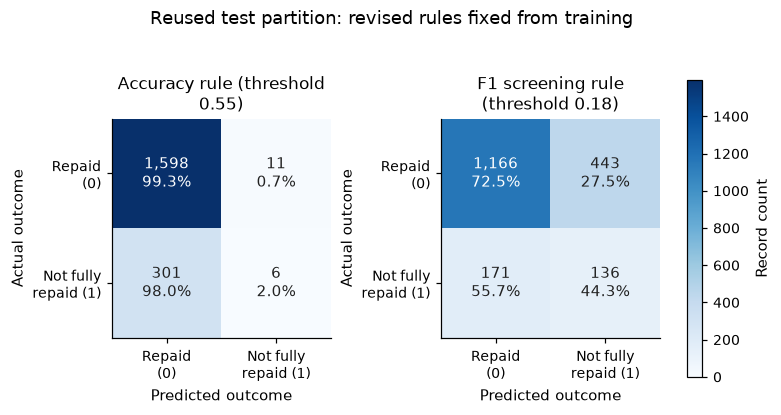

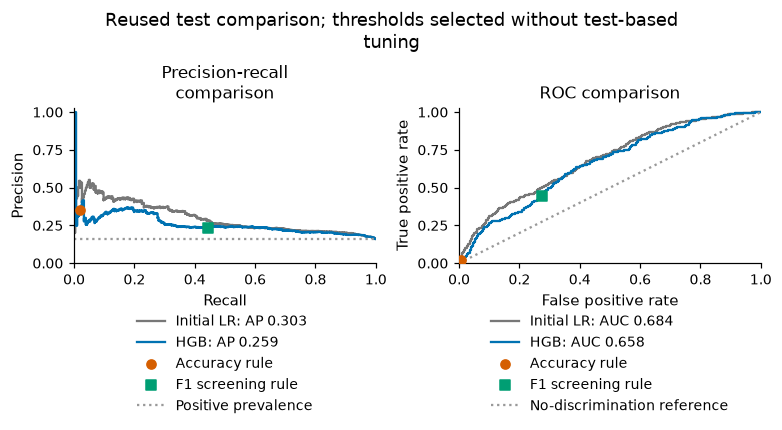

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(10.8, 4.7), layout="constrained")
vmax = max(revision_test_confusions[name].max() for name in ["Accuracy rule", "F1 screening rule"])
for ax, name, threshold in zip(axes, ["Accuracy rule", "F1 screening rule"],
                               [accuracy_rule_threshold, screening_rule_threshold]):
    matrix = revision_test_confusions[name]
    image = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=vmax)
    for actual in range(2):
        for predicted in range(2):
            count = int(matrix[actual, predicted])
            ax.text(predicted, actual, f"{count:,}\n{100 * count / matrix[actual].sum():.1f}%",
                    ha="center", va="center", fontsize=10,
                    color="white" if count > vmax * 0.55 else "#222222")
    ax.set_xticks([0, 1], ["Repaid\n(0)", "Not fully\nrepaid (1)"])
    ax.set_yticks([0, 1], ["Repaid\n(0)", "Not fully\nrepaid (1)"])
    ax.set(xlabel="Predicted outcome", ylabel="Actual outcome",
           title=f"{name} (threshold {threshold:.2f})")
fig.colorbar(image, ax=axes, shrink=0.78, label="Record count")
fig.suptitle("Reused test partition: revised rules fixed from training", fontsize=12)
export_figure(fig, "revision_17_confusion_matrices.png")

fig, axes = plt.subplots(1, 2, figsize=(11.0, 5.0), layout="constrained")
for name, scores, color in [
    ("Initial LR", test_scores, "#777777"),
    ("HGB", revised_test_scores, "#0072B2"),
]:
    precision, recall, _ = precision_recall_curve(y_test, scores)
    fpr, tpr, _ = roc_curve(y_test, scores)
    axes[0].step(recall, precision, where="post", color=color,
                 label=f"{name}: AP {average_precision_score(y_test, scores):.3f}")
    axes[1].plot(fpr, tpr, color=color,
                 label=f"{name}: AUC {roc_auc_score(y_test, scores):.3f}")
for name, color, marker in [("Accuracy rule", "#D55E00", "o"), ("F1 screening rule", "#009E73", "s")]:
    matrix = revision_test_confusions[name]
    tneg, fpos, fneg, tpos = matrix.ravel()
    axes[0].scatter(revision_test_metrics.at[name, "Recall"], revision_test_metrics.at[name, "Precision"],
                    color=color, marker=marker, zorder=5, label=name)
    axes[1].scatter(fpos / (fpos + tneg), tpos / (tpos + fneg),
                    color=color, marker=marker, zorder=5, label=name)
axes[0].axhline(y_test.mean(), color="#999999", linestyle=":", label="Positive prevalence")
axes[1].plot([0, 1], [0, 1], color="#999999", linestyle=":",
             label="No-discrimination reference")
axes[0].set(xlabel="Recall", ylabel="Precision", title="Precision-recall comparison")
axes[1].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC comparison")
for ax in axes:
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.03)
    ax.legend(fontsize=9, loc="best", framealpha=1)
    ax.grid(alpha=0.15)
fig.suptitle("Reused test comparison; thresholds selected without test-based tuning", fontsize=12)
export_figure(fig, "revision_18_ranking_curves.png")


### 10.4 Four-Factor Error Summaries and Final Integrity Checks

In [59]:
revision_error_frames = []
for name, prediction in [("Accuracy rule", revised_test_predictions), ("F1 screening rule", screening_test_predictions)]:
    groups = np.select([
        (test_actual_array == 0) & (prediction == 0),
        (test_actual_array == 0) & (prediction == 1),
        (test_actual_array == 1) & (prediction == 0),
        (test_actual_array == 1) & (prediction == 1),
    ], ERROR_ORDER, default="Unexpected")
    for group in ERROR_ORDER:
        values = X_test.loc[groups == group, FOCUS_FACTORS].copy()
        values["int.rate"] *= 100
        revision_error_frames.append({
            "Rule": name, "Error group": group, "Records": len(values),
            **{f"{field} median": float(values[field].median()) for field in FOCUS_FACTORS},
        })
revision_error_summary = pd.DataFrame(revision_error_frames)
display(revision_error_summary.round(4))

assert len(accuracy_threshold_results) == len(accuracy_candidates) * len(ACCURACY_THRESHOLDS)
assert (nested_coverage == 1).all() and len(nested_selection) == OUTER_FOLDS
assert set(X_train.index).isdisjoint(X_test.index)
assert accuracy_candidate_index == int(ranked_accuracy(accuracy_threshold_results).iloc[0]["Candidate"])
for name, (_, prediction) in revision_test_rules.items():
    matrix = revision_test_confusions[name]
    manual_accuracy = np.trace(matrix) / matrix.sum()
    np.testing.assert_allclose(manual_accuracy, revision_test_metrics.at[name, "Accuracy"])
    assert matrix.sum() == len(X_test)
    assert np.unique(prediction).size <= 2
np.testing.assert_array_equal((np.array([0.5, 0.51]) > 0.5).astype(int), [0, 1])
assert json.loads(SELECTION_PATH.read_text(encoding="utf-8")) == revised_frozen_selection
assert hashlib.sha256(SELECTION_PATH.read_bytes()).hexdigest() == revised_selection_sha256
assert hashlib.sha256(SOURCE_PATH.read_bytes()).hexdigest() == source_sha256
assert hashlib.sha256(DB_PATH.read_bytes()).hexdigest() == evaluation_database_sha256
assert len(figure_paths) == 18 and all(path.is_file() for path in figure_paths)
assert clone(revision_preprocessors["log_scaled"]).fit_transform(X_train).shape == (7662, 19)
# Deterministic refitting checks the full-training score vector without using scores for selection.
with threadpool_limits(limits=1):
    rerun_model = clone(revised_template).fit(X_train, y_train)
    np.testing.assert_allclose(rerun_model.predict_proba(X_test)[:, POSITIVE_CLASS],
                               revised_test_scores, rtol=1e-12, atol=1e-12)
print("Revision checks passed: unchanged observations/database, nested coverage, strict rules,")
print("manual metrics, frozen selection, reproducible fit and 18 exported figures.")


,Rule,Error group,Records,fico median,dti median,int.rate median,log.annual.inc median
0,Accuracy rule,TN,1598,707.0,12.560,12.18,10.9475
1,Accuracy rule,FP,11,667.0,20.150,14.38,11.3145
2,Accuracy rule,FN,301,692.0,13.300,13.16,10.8396
3,Accuracy rule,TP,6,667.0,12.165,14.46,10.6414
4,F1 screening rule,TN,1166,717.0,12.365,11.48,11.0021
5,F1 screening rule,FP,443,687.0,13.590,13.62,10.8628
6,F1 screening rule,FN,171,702.0,12.940,12.53,10.8590
7,F1 screening rule,TP,136,679.5,14.045,14.22,10.8198


Revision checks passed: unchanged observations/database, nested coverage, strict rules,
manual metrics, frozen selection, reproducible fit and 18 exported figures.
